### CẤU HÌNH LOGGING (GHI RA CONSOLE + FILE LOG)

In [1]:
from pathlib import Path
import logging
import sys
import os

def find_project_root(start=None):
    """Find the Practice 4 root from the current working directory."""
    start = Path(start or Path.cwd()).resolve()
    marker = Path("datasets") / "processed" / "electricity_load_weather_hourly.csv"
    candidates = [start, *start.parents]
    candidates.extend(
        base / relative
        for base in (start, *start.parents)
        for relative in (Path("total_practice") / "Practice_4", Path("Practice_4"))
    )
    for candidate in candidates:
        if (candidate / marker).is_file():
            return candidate
    raise FileNotFoundError(
        "Không tìm thấy project root chứa datasets/processed/electricity_load_weather_hourly.csv"
    )

PROJECT_ROOT = find_project_root()
LOG_DIR = PROJECT_ROOT / "docs" / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = LOG_DIR / "practice4.log"

log = logging.getLogger("Practice4")
log.setLevel(logging.INFO)
log.propagate = False

# Xóa handler cũ nếu chạy lại cell trong Jupyter
if log.hasHandlers():
    log.handlers.clear()

formatter = logging.Formatter(
    fmt="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S"
)

file_handler = logging.FileHandler(
    LOG_FILE,
    mode="w",
    encoding="utf-8"
)
file_handler.setFormatter(formatter)

log.addHandler(file_handler)
log.info("Khởi tạo hệ thống logging thành công.")
log.info("Log file: %s", LOG_FILE.resolve())

### Khởi tạo thư viện

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from IPython.display import display
from pathlib import Path

color_pal = sns.color_palette()

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

TABLE_STYLES = [
    {"selector": "table", "props": [("border-collapse", "separate"), ("border-spacing", "0"), ("font-size", "14px"), ("margin", "0.4rem 0 1.2rem 0"), ("max-width", "100%")]},
    {"selector": "caption", "props": [("caption-side", "top"), ("color", "#1f4e78"), ("font-size", "17px"), ("font-weight", "600"), ("padding", "10px 0"), ("text-align", "left")]},
    {"selector": "thead th", "props": [("background-color", "#1f4e78"), ("color", "#ffffff"), ("padding", "10px 14px"), ("text-align", "left"), ("border", "1px solid #5b9bd5")]},
    {"selector": "tbody td", "props": [("background-color", "#f8fafc"), ("color", "#172033"), ("padding", "9px 14px"), ("border-bottom", "1px solid #d8e1eb"), ("vertical-align", "middle")]},
    {"selector": "tbody tr:nth-child(even) td", "props": [("background-color", "#eaf2fb")]},
    {"selector": "tbody tr:hover td", "props": [("background-color", "#dbeafe")]},
    {"selector": "tbody td:first-child", "props": [("font-weight", "500"), ("white-space", "nowrap")]},
]

def style_table(dataframe, *, caption, formats=None, row_highlighter=None):
    styled = (
        dataframe.style.hide(axis="index")
        .set_table_styles(TABLE_STYLES)
        .set_caption(caption)
    )
    numeric_columns = dataframe.select_dtypes(include="number").columns.tolist()
    if numeric_columns:
        styled = styled.set_properties(subset=numeric_columns, **{"text-align": "right", "font-variant-numeric": "tabular-nums"})
    if formats:
        styled = styled.format(formats)
    if row_highlighter:
        styled = styled.apply(row_highlighter, axis=1)
    return styled

## Phase 1 — Data Preparation

### Đọc dữ liệu

Canonical dataset giữ nguyên các `load` target bị thiếu để tránh dùng giá trị tương lai trong bước xây dựng dữ liệu. Khi chuẩn bị model input, notebook chỉ forward-fill theo quá khứ; các mốc có target gốc bị thiếu được đánh dấu và loại khỏi validation/test metrics.

In [3]:
DATA_PATH = PROJECT_ROOT / "datasets"
processed_file = DATA_PATH / "processed" / "electricity_load_weather_hourly.csv"

In [4]:
df = pd.read_csv(processed_file)
required_cols = ["time", "load", "temperature", "humidity", "wind_speed"]
missing_cols = sorted(set(required_cols) - set(df.columns))
if missing_cols:
    raise ValueError(f"Processed dataset thiếu cột bắt buộc: {missing_cols}")

parsed_time = pd.to_datetime(df["time"], utc=True)
if parsed_time.isna().any():
    raise ValueError("Timestamp chứa giá trị không hợp lệ sau khi parse.")
if not parsed_time.is_monotonic_increasing:
    raise ValueError("Timestamp đầu vào không tăng dần; không tự động sắp xếp.")
duplicate_timestamps = int(parsed_time.duplicated().sum())
if duplicate_timestamps:
    raise ValueError(f"Phát hiện {duplicate_timestamps} timestamp trùng; không tự động loại bỏ.")
df["time"] = parsed_time
df = df.reset_index(drop=True)
num_cols = ["load", "temperature", "humidity", "wind_speed"]

missing_summary = df[required_cols].isna().sum()
missing_load_count = int(missing_summary["load"])
if missing_load_count:
    log.warning(
        "Canonical dataset giữ nguyên %d missing load target; notebook sẽ dùng xử lý causal past-only cho input và loại target thiếu khỏi metrics.",
        missing_load_count,
    )
non_target_missing = missing_summary.drop(labels=["load"])
if non_target_missing.any():
    raise ValueError(
        "Processed dataset còn missing ở biến đầu vào: "
        f"{non_target_missing[non_target_missing > 0].to_dict()}"
    )

time_diffs = df["time"].diff().dropna()
unexpected_intervals = time_diffs[time_diffs != pd.Timedelta(hours=1)]
if not unexpected_intervals.empty:
    log.warning(
        "Phát hiện %d khoảng thời gian không phải 1 giờ; cần kiểm tra trước modeling.",
        len(unexpected_intervals)
    )

data_quality_summary = pd.DataFrame({
    "Rows": [len(df)],
    "Columns": [df.shape[1]],
    "Duplicate timestamps": [duplicate_timestamps],
    "Missing values": [int(missing_summary.sum())],
    "Missing load targets": [missing_load_count],
    "Unexpected intervals": [len(unexpected_intervals)],
    "Start": [df["time"].min()],
    "End": [df["time"].max()],
})
log.info("Processed data quality summary:\n%s", data_quality_summary.to_string(index=False))

def highlight_quality(row):
    passed = row["Duplicate timestamps"] == 0 and row["Unexpected intervals"] == 0 and row["Missing load targets"] == 0
    color = "#dcfce7" if passed else "#fee2e2"
    return [f"background-color: {color}"] * len(row)

display(style_table(data_quality_summary, caption="Phase 1 — Processed data quality audit", row_highlighter=highlight_quality))
display(style_table(df.head(), caption="Phase 1 — Processed dataset preview"))

Rows,Columns,Duplicate timestamps,Missing values,Missing load targets,Unexpected intervals,Start,End
35064,5,0,36,36,0,2014-12-31 23:00:00+00:00,2018-12-31 22:00:00+00:00


time,load,temperature,humidity,wind_speed
2014-12-31 23:00:00+00:00,25385.000000,-5.825000,63.000000,1.000000
2015-01-01 00:00:00+00:00,24382.000000,-5.825000,63.000000,1.000000
2015-01-01 01:00:00+00:00,22734.000000,-6.964000,64.000000,1.000000
2015-01-01 02:00:00+00:00,21286.000000,-6.964000,64.000000,1.000000
2015-01-01 03:00:00+00:00,20264.000000,-6.964000,64.000000,1.000000


## Phase 2 — Temporal Split và Validation Design

### **Chia dữ liệu theo thời gian**


In [5]:
from sklearn.preprocessing import StandardScaler

# Tạo bản sao riêng để chia tập và modeling
# Chỉ dùng thông tin quá khứ để lấp load thiếu trong input; target gốc
# vẫn được đánh dấu để loại khỏi validation/test metrics.
df_model = df.copy()
df_model["load_observed"] = df_model["load"].notna()
df_model["load"] = df_model["load"].ffill()
if df_model["load"].isna().any():
    raise ValueError("Không thể tạo causal load input vì thiếu giá trị ở đầu chuỗi.")
log.info(
    "Causal load treatment: forward-fill past-only; missing targets excluded from metrics: %d",
    int((~df_model["load_observed"]).sum()),
)


In [6]:
# Xác định vị trí chia dữ liệu
n = len(df_model)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Chia dữ liệu theo thứ tự thời gian, không shuffle
train_df = df_model.iloc[:train_end].copy()
val_df = df_model.iloc[train_end:val_end].copy()
test_df = df_model.iloc[val_end:].copy()

# Raw split chỉ dùng cho audit chất lượng; model split dùng causal-filled input.
raw_train_df = df.iloc[:train_end].copy()
raw_val_df = df.iloc[train_end:val_end].copy()
raw_test_df = df.iloc[val_end:].copy()

In [7]:
# Kiểm tra kích thước các tập
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Samples": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "Percentage": [
        len(train_df) / n * 100,
        len(val_df) / n * 100,
        len(test_df) / n * 100
    ],
    "Start Time": [
        train_df["time"].min(),
        val_df["time"].min(),
        test_df["time"].min()
    ],
    "End Time": [
        train_df["time"].max(),
        val_df["time"].max(),
        test_df["time"].max()
    ]
})

display(style_table(
    split_summary,
    caption="Phase 2 — Chronological train/validation/test split",
    formats={"Percentage": "{:.2f}%"}
))

log.info("Hoàn thành chia dữ liệu theo thời gian.")
log.info("Train: %d | Validation: %d | Test: %d",
         len(train_df), len(val_df), len(test_df))
log.info(
    "Missing load targets by split | Train: %d | Validation: %d | Test: %d",
    int((~train_df["load_observed"]).sum()),
    int((~val_df["load_observed"]).sum()),
    int((~test_df["load_observed"]).sum()),
)

Dataset,Samples,Percentage,Start Time,End Time
Train,24544,70.00%,2014-12-31 23:00:00+00:00,2017-10-19 14:00:00+00:00
Validation,5260,15.00%,2017-10-19 15:00:00+00:00,2018-05-26 18:00:00+00:00
Test,5260,15.00%,2018-05-26 19:00:00+00:00,2018-12-31 22:00:00+00:00


In [8]:
log.info("Khởi tạo cấu hình hiển thị biểu đồ thành công.")

log.info("Bắt đầu đọc dữ liệu từ: %s", processed_file)

log.info("Đọc dữ liệu thành công.")
log.info("Kích thước ban đầu: %d dòng x %d cột", df.shape[0], df.shape[1])

log.info("Chuyển đổi cột time sang datetime thành công.")
log.info(
    "Khoảng thời gian dữ liệu: %s -> %s",
    df["time"].min(),
    df["time"].max()
)

log.info("Danh sách cột dữ liệu:")
log.info("%s", df.columns.tolist())

log.info("Số lượng giá trị thiếu trên raw Train trước causal treatment:")
log.info("%s", raw_train_df.isna().sum().to_string())

time_diffs = train_df["time"].diff().dropna().value_counts()
log.info("Phân bố bước nhảy thời gian trên Train:")
log.info("%s", time_diffs.to_string())

desc = train_df[num_cols].describe().T.round(2)
log.info("Thống kê mô tả các biến số trên Train:")
log.info("%s", desc.to_string())

log.info("Hoàn thành bước khám phá tổng quan dữ liệu.")

In [9]:
print("=== TỔNG QUAN DỮ LIỆU ===")
print(f"Kích thước toàn bộ file: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Khoảng thời gian toàn bộ file: {df['time'].min()} -> {df['time'].max()}")

print("\n=== KIỂM TRA DỮ LIỆU TRAIN ===")
print(f"Kích thước Train: {train_df.shape[0]:,} dòng")
print(f"Khoảng thời gian Train: {train_df['time'].min()} -> {train_df['time'].max()}")
print("Kiểm tra bước nhảy thời gian trên Train:")
print(train_df["time"].diff().value_counts())

print("\nThống kê mô tả trên Train:")
display(style_table(desc.reset_index().rename(columns={"index": "Feature"}), caption="Phase 3 — Training-only descriptive statistics", formats={"mean": "{:.2f}", "std": "{:.2f}", "min": "{:.2f}", "25%": "{:.2f}", "50%": "{:.2f}", "75%": "{:.2f}", "max": "{:.2f}"}))


=== TỔNG QUAN DỮ LIỆU ===
Kích thước toàn bộ file: 35,064 dòng x 5 cột
Khoảng thời gian toàn bộ file: 2014-12-31 23:00:00+00:00 -> 2018-12-31 22:00:00+00:00

=== KIỂM TRA DỮ LIỆU TRAIN ===
Kích thước Train: 24,544 dòng
Khoảng thời gian Train: 2014-12-31 23:00:00+00:00 -> 2017-10-19 14:00:00+00:00
Kiểm tra bước nhảy thời gian trên Train:
time
0 days 01:00:00    24543
Name: count, dtype: int64

Thống kê mô tả trên Train:


Feature,count,mean,std,min,25%,50%,75%,max
load,24544.000000,28551.83,4536.51,18041.00,24676.00,28811.50,31978.00,41015.00
temperature,24544.000000,15.74,9.45,-9.02,8.56,14.51,22.57,40.18
humidity,24544.000000,56.74,24.96,0.00,35.00,57.00,79.00,100.00
wind_speed,24544.000000,2.46,1.99,0.00,1.00,2.00,3.00,18.00


## Phase 3 — Exploratory Data Analysis

### Kiểm tra Missing Values, Dữ liệu trùng lặp & Lỗi cảm biến

In [10]:
missing_summary = pd.DataFrame({
    "Missing Count": raw_train_df.isnull().sum(),
    "Missing (%)": (raw_train_df.isnull().mean() * 100).round(4)
})
log.info("Bảng kiểm tra Missing Values trên Train:\n%s", missing_summary.to_string())
def highlight_missing(row):
    color = "#fee2e2" if row["Missing Count"] > 0 else "#dcfce7"
    return [f"background-color: {color}"] * len(row)

display(style_table(missing_summary.reset_index().rename(columns={"index": "Feature"}), caption="Phase 3 — Missing values on training data", formats={"Missing (%)": "{:.4f}%"}, row_highlighter=highlight_missing))

Feature,Missing Count,Missing (%)
time,0,0.0000%
load,32,0.1304%
temperature,0,0.0000%
humidity,0,0.0000%
wind_speed,0,0.0000%


In [11]:
dup_rows = int(raw_train_df.duplicated().sum())
dup_times = int(raw_train_df["time"].duplicated().sum())

log.info(
    "Train | Số dòng trùng lặp hoàn toàn: %d | Số mốc thời gian trùng lặp: %d",
    dup_rows, dup_times
)

print(f"Train - Duplicate rows: {dup_rows}")
print(f"Train - Duplicate timestamps: {dup_times}")


Train - Duplicate rows: 0
Train - Duplicate timestamps: 0


In [12]:
# Kiểm tra bất thường cảm biến ẩn (cả temperature và humidity cùng rơi về 0)
sensor_anomalies = train_df[(train_df["temperature"] == 0) & (train_df["humidity"] == 0)]
if not sensor_anomalies.empty:
    log.warning(
        "Phát hiện %d điểm nghi ngờ lỗi cảm biến (temperature == 0 & humidity == 0):\n%s",
        len(sensor_anomalies),
        sensor_anomalies[["time", "load", "temperature", "humidity", "wind_speed"]].to_string()
    )
    display(sensor_anomalies[["time", "load", "temperature", "humidity", "wind_speed"]])

,time,load,temperature,humidity,wind_speed
2116,2015-03-30 03:00:00+00:00,21335.0,0.0,0.0,1.0
2124,2015-03-30 11:00:00+00:00,31578.0,0.0,0.0,3.0


#### **Kiểm tra Outliers**

In [13]:
outlier_rows = []
for col in num_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_low = int((train_df[col] < lower).sum())
    n_high = int((train_df[col] > upper).sum())
    pct = round((n_low + n_high) / len(train_df) * 100, 2)

    outlier_rows.append({
        "Feature": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Low Outliers": n_low,
        "High Outliers": n_high,
        "Outlier (%)": pct
    })
    log.info(
        "Train | Biến %-11s | IQR Bounds=[%.2f, %.2f] | Low=%d, High=%d (%.2f%%)",
        col, lower, upper, n_low, n_high, pct
    )

In [14]:
outlier_df = pd.DataFrame(outlier_rows)

def highlight_outliers(row):
    color = "#fef3c7" if row["Outlier (%)"] > 0 else "#dcfce7"
    return [f"background-color: {color}"] * len(row)

display(style_table(outlier_df, caption="Phase 3 — Training-only outlier audit", formats={"Lower Bound": "{:.2f}", "Upper Bound": "{:.2f}", "Outlier (%)": "{:.2f}%"}, row_highlighter=highlight_outliers))

Feature,Lower Bound,Upper Bound,Low Outliers,High Outliers,Outlier (%)
load,13723.00,42931.00,0,0,0.00%
temperature,-12.44,43.58,0,0,0.00%
humidity,-31.00,145.00,0,0,0.00%
wind_speed,-2.00,6.00,0,1232,5.02%


#### Vẽ Boxpllot cho Outliers

In [15]:
def create_features(df):
    """
    Tạo các đặc trưng chuỗi thời gian dựa trên cột thời gian.
    """
    df = df.copy()

    df["hour"] = df["time"].dt.hour
    df["dayofweek"] = df["time"].dt.dayofweek
    df["quarter"] = df["time"].dt.quarter
    df["month"] = df["time"].dt.month
    df["year"] = df["time"].dt.year
    df["dayofyear"] = df["time"].dt.dayofyear
    df["is_weekend"] = df["dayofweek"].isin([5, 6])

    return df

In [16]:
train_features = create_features(train_df)
train_features.head()


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_54107/561940018.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dayofweek"] = df["time"].dt.dayofweek
/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_54107/561940018.py:12: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["dayofyear"] = df["time"].dt.dayofyear


,time,load,temperature,humidity,wind_speed,load_observed,hour,dayofweek,quarter,month,year,dayofyear,is_weekend
0,2014-12-31 23:00:00+00:00,25385.0,-5.825,63.0,1.0,True,23,2,4,12,2014,365,False
1,2015-01-01 00:00:00+00:00,24382.0,-5.825,63.0,1.0,True,0,3,1,1,2015,1,False
2,2015-01-01 01:00:00+00:00,22734.0,-6.964,64.0,1.0,True,1,3,1,1,2015,1,False
3,2015-01-01 02:00:00+00:00,21286.0,-6.964,64.0,1.0,True,2,3,1,1,2015,1,False
4,2015-01-01 03:00:00+00:00,20264.0,-6.964,64.0,1.0,True,3,3,1,1,2015,1,False


Text(0.5, 1.0, 'Load by Hour')

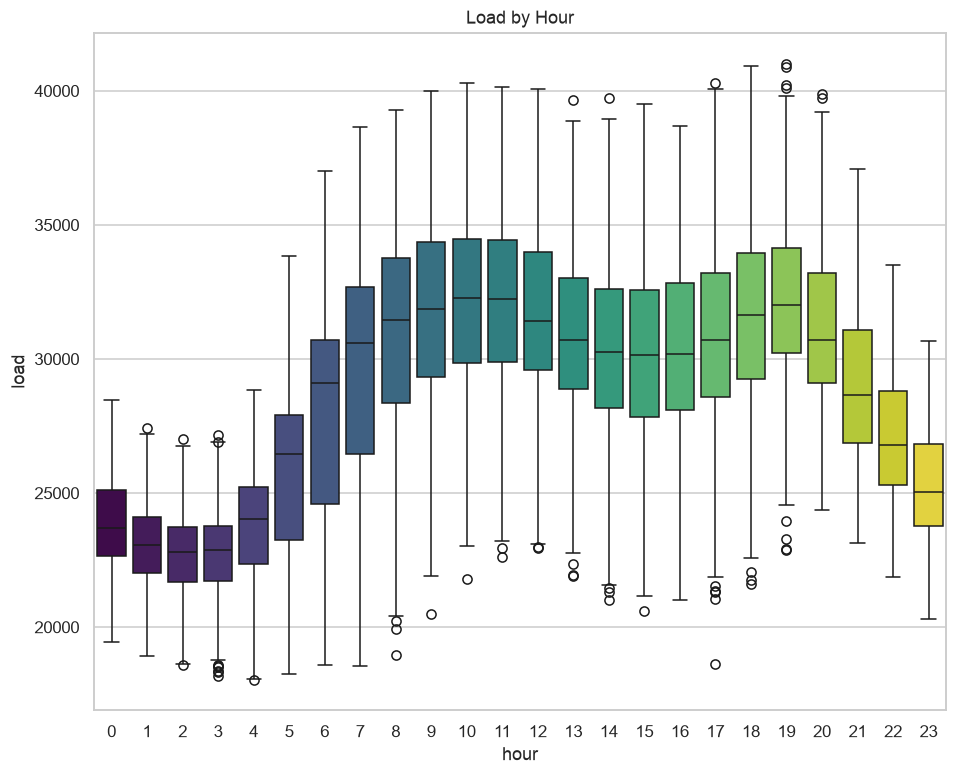

In [17]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=train_features,
    x="hour",
    y="load",
    hue="hour",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Hour")

Text(0.5, 1.0, 'Load by Day of Week')

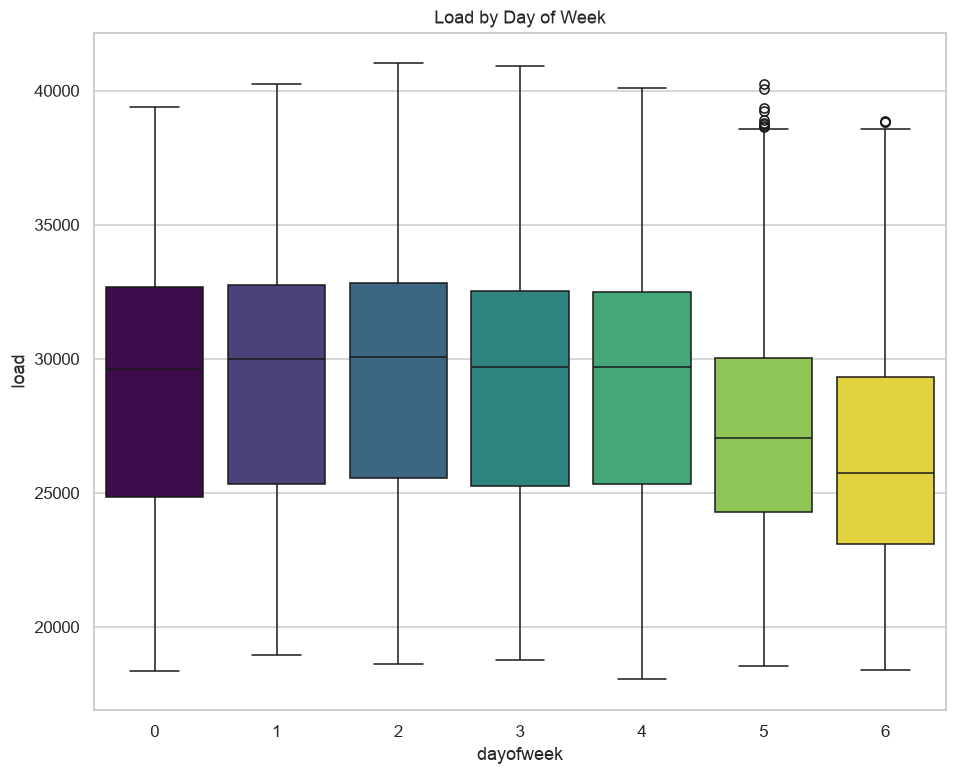

In [18]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=train_features,
    x="dayofweek",
    y="load",
    hue="dayofweek",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Day of Week")

Text(0.5, 1.0, 'Load by Month')

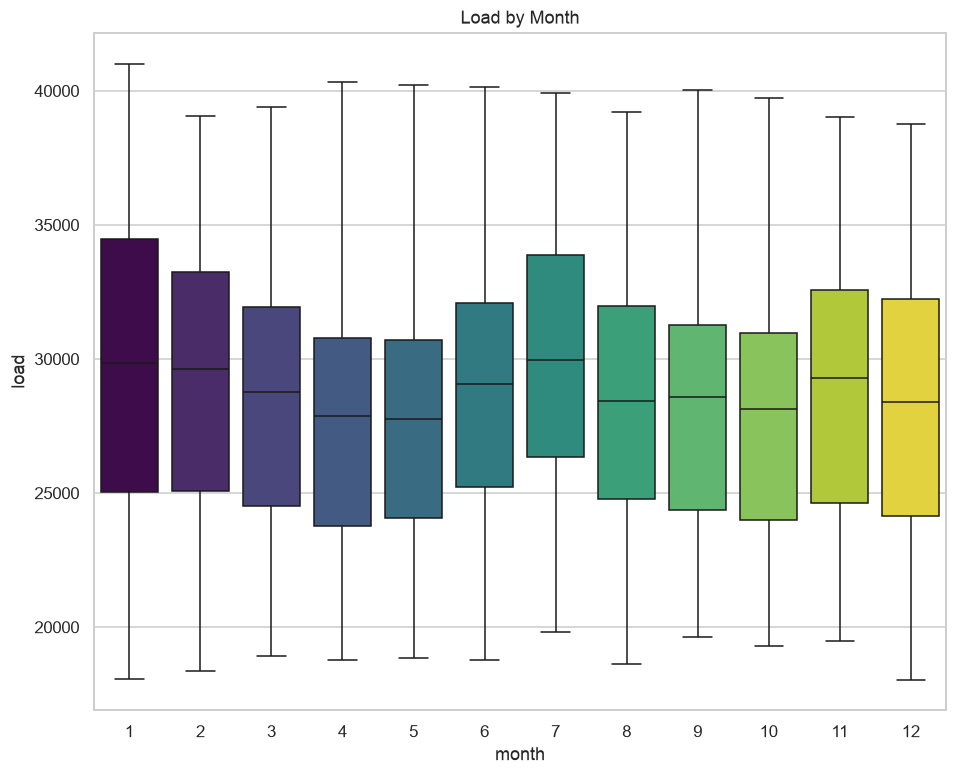

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.boxplot(
    data=train_features,
    x="month",
    y="load",
    hue="month",
    palette="viridis",
    legend=False
)
ax.set_title("Load by Month")

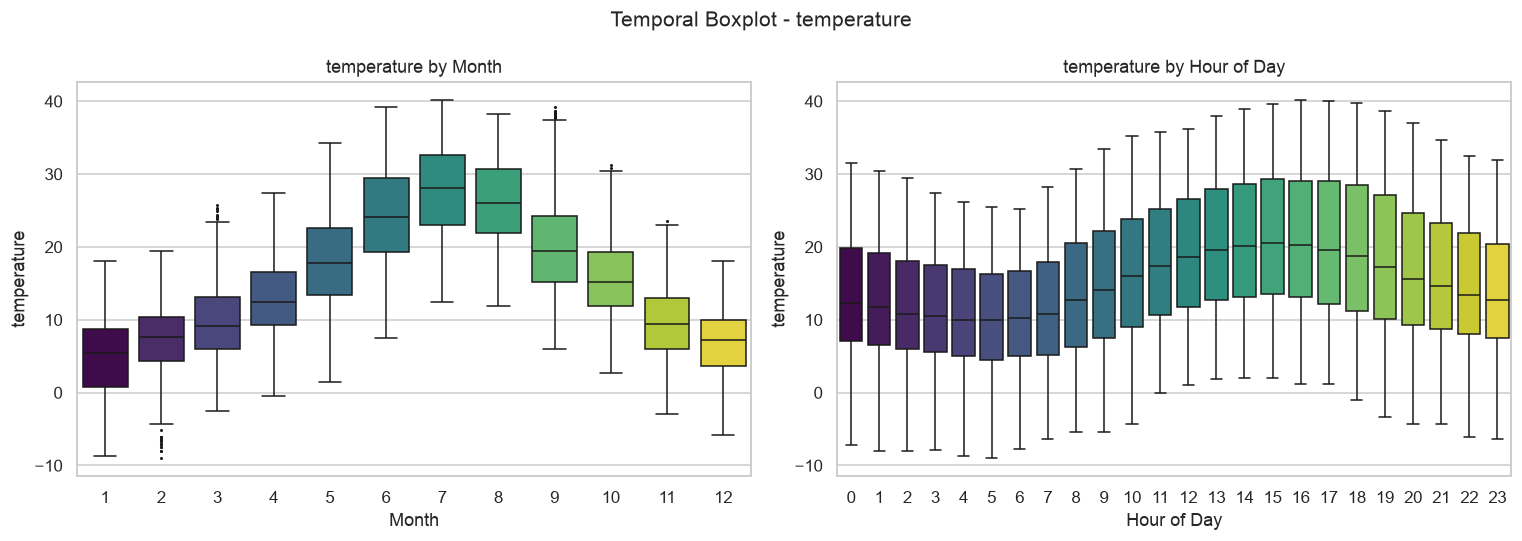

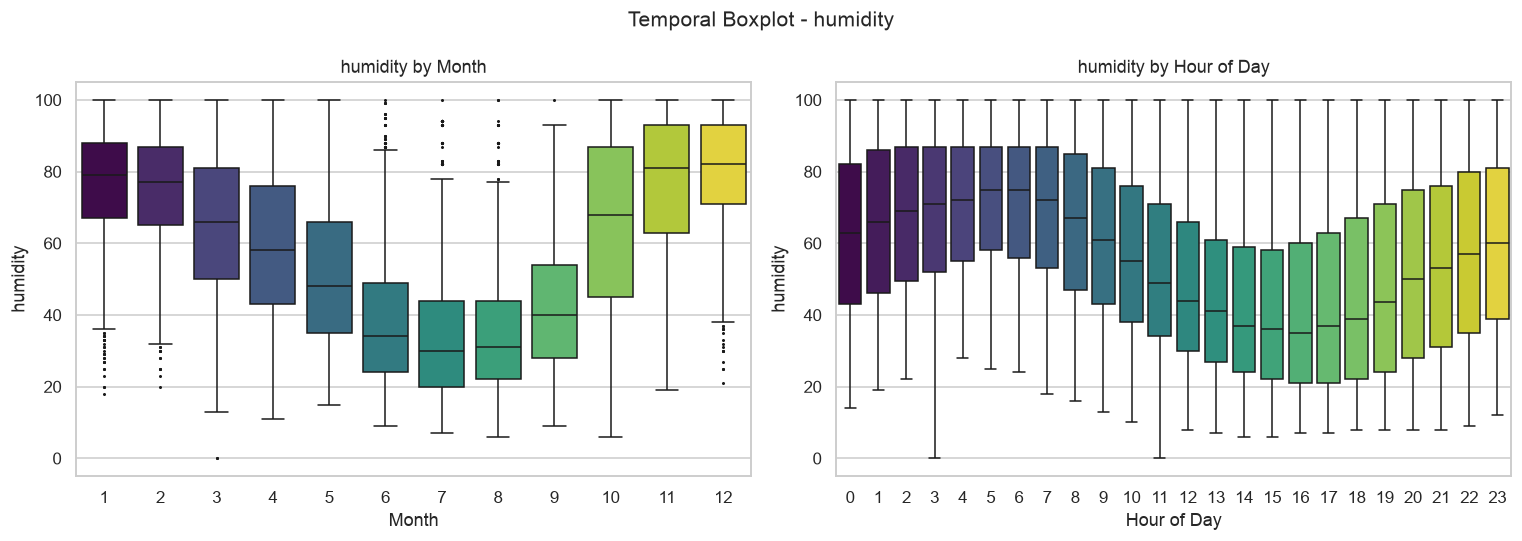

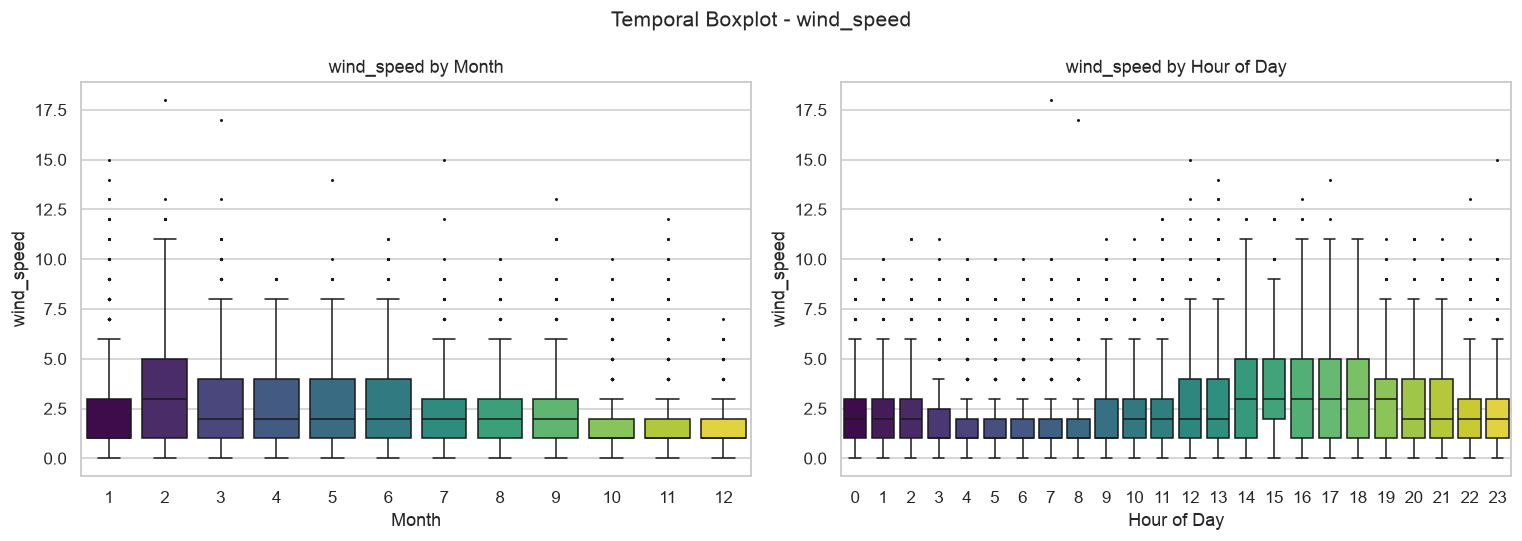

In [20]:
# Các đặc trưng thời gian dùng để phân tích từng biến
temporal_groups = {
    "temperature": ["month", "hour"],
    "humidity": ["month", "hour"],
    "wind_speed": ["month", "hour"]
}

orders = {
    "month": list(range(1, 13)),
    "hour": list(range(24))
}

group_labels = {
    "month": "Month",
    "hour": "Hour of Day"
}

# Vẽ boxplot riêng cho từng biến
for col, groups in temporal_groups.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, group in zip(axes, groups):
        sns.boxplot(
            data=train_features,
            x=group,
            y=col,
            hue=group,
            order=orders[group],
            hue_order=orders[group],
            palette="viridis",
            legend=False,
            dodge=False,
            ax=ax,
            showfliers=True,
            fliersize=1
        )
        ax.set_title(f"{col} by {group_labels[group]}")
        ax.set_xlabel(group_labels[group])
        ax.set_ylabel(col)
    fig.suptitle(
        f"Temporal Boxplot - {col}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

#### **Biểu đồ điện năng tiêu thụ theo thời gian**

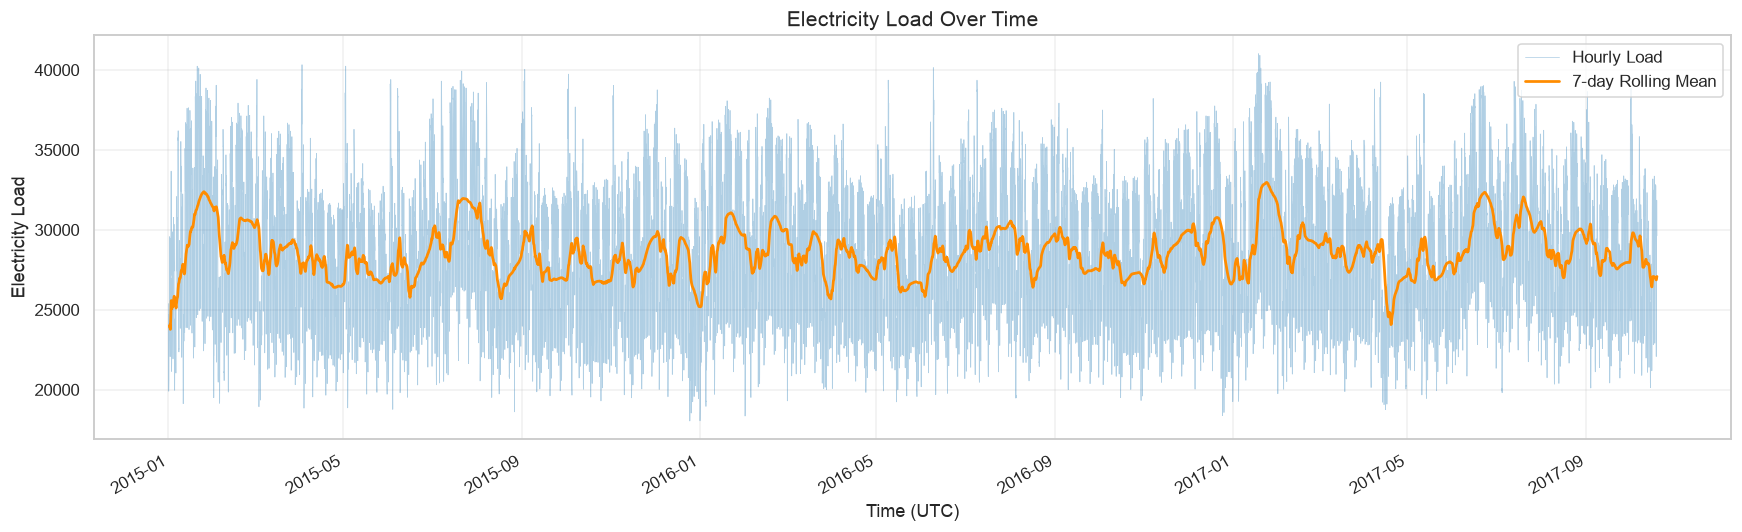

In [21]:
# Tính trung bình trượt 7 ngày (168 giờ)
load_series = train_df.set_index("time")["load"]
load_rolling = load_series.rolling(
    window=168,
    min_periods=24
).mean()

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(
    load_series.index,
    load_series,
    color=color_pal[0],
    linewidth=0.5,
    alpha=0.35,
    label="Hourly Load"
)
ax.plot(
    load_rolling.index,
    load_rolling,
    color="darkorange",
    linewidth=1.8,
    label="7-day Rolling Mean"
)
ax.set_title("Electricity Load Over Time", fontsize=14)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Electricity Load")
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

#### **Biểu đồ tương quan giữa Load và Temp**

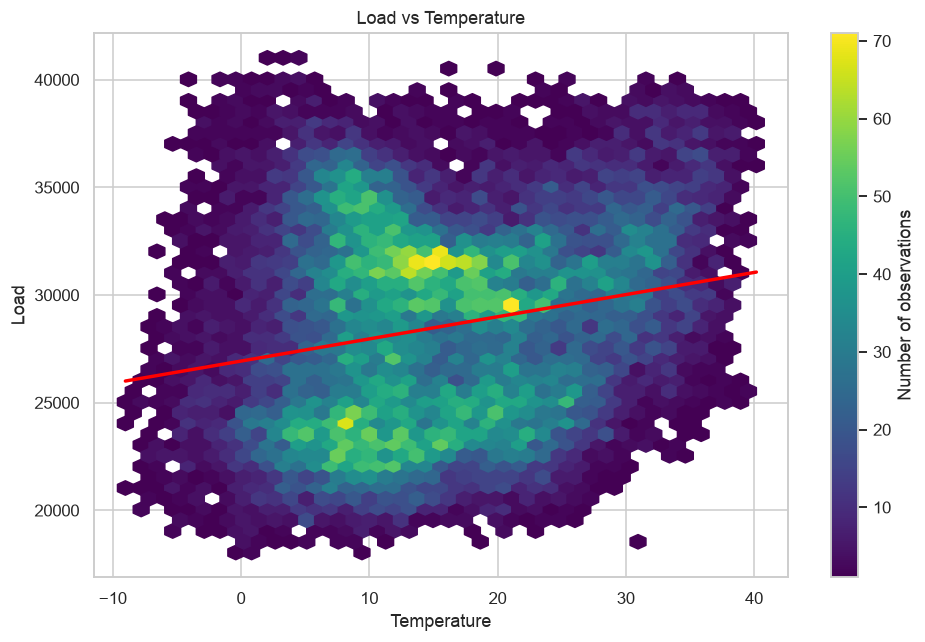

In [22]:
fig, ax = plt.subplots(figsize=(9, 6))

hb = ax.hexbin(
    train_df["temperature"],
    train_df["load"],
    gridsize=40,
    cmap="viridis",
    mincnt=1
)

plt.colorbar(hb, ax=ax, label="Number of observations")

sns.regplot(
    data=train_df,
    x="temperature",
    y="load",
    scatter=False,
    color="red",
    ci=None,
    ax=ax
)

ax.set_title("Load vs Temperature")
ax.set_xlabel("Temperature")
ax.set_ylabel("Load")

plt.tight_layout()
plt.show()


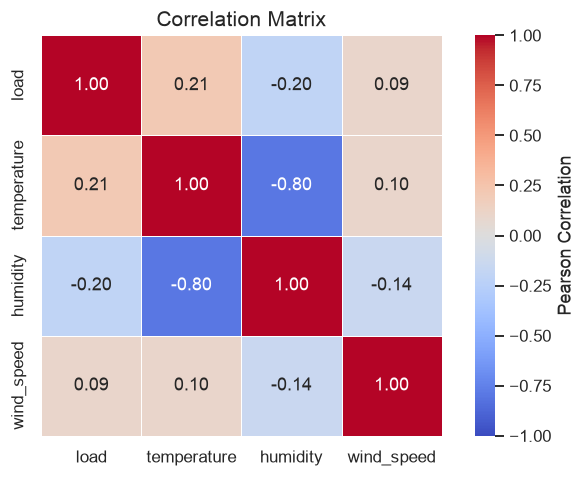

In [23]:
# Tính ma trận tương quan Pearson
corr_matrix = train_df[num_cols].corr(method="pearson")

# Vẽ heatmap
fig, ax = plt.subplots(figsize=(6.5, 4.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title("Correlation Matrix", fontsize=14)

plt.tight_layout()
plt.show()

# Ghi kết quả vào log
log.info(
    "Ma trận tương quan Pearson:\n%s",
    corr_matrix.round(3).to_string()
)

log.info("Hoàn thành Correlation Matrix.")

## Phase 4 — Preprocessing và Scaling

## **4. Preprocessing**

Missing `load` chỉ được xử lý bằng forward-fill past-only cho input; target gốc bị thiếu không được dùng làm ground truth khi tính metric. `StandardScaler` vẫn chỉ fit trên Train.

### **4.1 Chuẩn hóa dữ liệu (StandardScaler)**


In [24]:
# Khởi tạo StandardScaler
scaler = StandardScaler()

# Fit trên Train và transform cả ba tập
train_values = scaler.fit_transform(train_df[num_cols])

val_values = scaler.transform(val_df[num_cols])

test_values = scaler.transform(test_df[num_cols])

# Chuyển kết quả về DataFrame để giữ tên cột và timestamp
train_scaled = pd.DataFrame(
    train_values,
    columns=num_cols,
    index=pd.DatetimeIndex(train_df["time"], name="time")
)

val_scaled = pd.DataFrame(
    val_values,
    columns=num_cols,
    index=pd.DatetimeIndex(val_df["time"], name="time")
)

test_scaled = pd.DataFrame(
    test_values,
    columns=num_cols,
    index=pd.DatetimeIndex(test_df["time"], name="time")
)

log.info("Hoàn thành chuẩn hóa dữ liệu bằng StandardScaler.")

In [25]:
# Kiểm tra thống kê trên tập Train sau chuẩn hóa
print("=== TRAIN DATA AFTER SCALING ===")
display(style_table(train_scaled.describe().T.reset_index().rename(columns={"index": "Feature"}), caption="Phase 4 — Train data after StandardScaler", formats={"mean": "{:.3f}", "std": "{:.3f}", "min": "{:.3f}", "25%": "{:.3f}", "50%": "{:.3f}", "75%": "{:.3f}", "max": "{:.3f}"}))

print("=== VALIDATION DATA ===")
print("Shape:", val_scaled.shape)
display(style_table(val_scaled.head().reset_index(), caption="Phase 4 — Validation sample after scaling"))

print("=== TEST DATA ===")
print("Shape:", test_scaled.shape)

# Kiểm tra kích thước và thứ tự thời gian
assert len(train_scaled) + len(val_scaled) + len(test_scaled) == len(df)

assert train_scaled.index.max() < val_scaled.index.min()
assert val_scaled.index.max() < test_scaled.index.min()

assert train_scaled.index.is_monotonic_increasing
assert val_scaled.index.is_monotonic_increasing
assert test_scaled.index.is_monotonic_increasing

log.info("Kiểm tra dữ liệu sau Preprocessing thành công.")


=== TRAIN DATA AFTER SCALING ===


Feature,count,mean,std,min,25%,50%,75%,max
load,24544.000000,-0.000,1.000,-2.317,-0.854,0.057,0.755,2.747
temperature,24544.000000,0.000,1.000,-2.621,-0.759,-0.130,0.723,2.588
humidity,24544.000000,0.000,1.000,-2.273,-0.871,0.010,0.892,1.733
wind_speed,24544.000000,-0.000,1.000,-1.238,-0.735,-0.232,0.271,7.817


=== VALIDATION DATA ===
Shape: (5260, 4)


time,load,temperature,humidity,wind_speed
2017-10-19 15:00:00+00:00,0.272278,0.193910,-0.470379,-0.231607
2017-10-19 16:00:00+00:00,0.260154,0.236258,-0.189957,1.277571
2017-10-19 17:00:00+00:00,0.530191,0.217202,0.090465,1.277571
2017-10-19 18:00:00+00:00,0.920588,0.025574,0.250706,0.774511
2017-10-19 19:00:00+00:00,0.689568,-0.164995,0.571189,-0.231607


=== TEST DATA ===
Shape: (5260, 4)


## Phase 5 — Feature Engineering

### **5. Feature Engineering cho ML và DL**

#### **Chuẩn bị dữ liệu cho LSTM**

In [26]:
# Hàm tạo Lag Window
def create_lstm_sequences(data, history=None, window_size=24):
    """
    Tạo chuỗi dữ liệu 3D cho LSTM.
    Mỗi mẫu sử dụng 24 giờ trước để dự báo load ở giờ tiếp theo.
    """

    # Ghép dữ liệu lịch sử nếu cần tạo window cho Validation/Test
    if history is not None:
        data_all = pd.concat([history.tail(window_size), data])
        start_pos = window_size
    else:
        data_all = data.copy()
        start_pos = window_size

    values = data_all[num_cols].to_numpy(dtype=np.float32)

    X, y = [], []

    for i in range(start_pos, len(data_all)):
        X.append(values[i - window_size:i])
        y.append(values[i, num_cols.index("load")])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )

In [27]:
# Tạo Lag Window cho từng tập dữ liệu
X_train_lstm, y_train_lstm = create_lstm_sequences(
    train_scaled
)

X_val_lstm, y_val_lstm = create_lstm_sequences(
    val_scaled,
    history=train_scaled
)

X_test_lstm, y_test_lstm = create_lstm_sequences(
    test_scaled,
    history=pd.concat([train_scaled, val_scaled])
)

# Chỉ giữ các mẫu có target quan sát được; các load bị forward-fill
# chỉ được phép xuất hiện trong lịch sử đầu vào, không làm ground truth.
train_lstm_observed = train_df["load_observed"].to_numpy()[24:]
val_lstm_observed = val_df["load_observed"].to_numpy()
test_lstm_observed = test_df["load_observed"].to_numpy()
X_train_lstm, y_train_lstm = X_train_lstm[train_lstm_observed], y_train_lstm[train_lstm_observed]
X_val_lstm, y_val_lstm = X_val_lstm[val_lstm_observed], y_val_lstm[val_lstm_observed]
X_test_lstm, y_test_lstm = X_test_lstm[test_lstm_observed], y_test_lstm[test_lstm_observed]

# Kiểm tra kích thước
print("Train:", X_train_lstm.shape, y_train_lstm.shape)
print("Validation:", X_val_lstm.shape, y_val_lstm.shape)
print("Test:", X_test_lstm.shape, y_test_lstm.shape)

log.info("Hoàn thành tạo Lag Window cho LSTM.")

Train: (24488, 24, 4) (24488,)
Validation: (5258, 24, 4) (5258,)
Test: (5258, 24, 4) (5258,)


#### **Rolling Features – Chỉ sử dụng cho XGBoost**

In [28]:
def create_xgb_features(data, history=None, window_size=24):
    """
    Tạo Lag Features và Rolling Features cho XGBoost.
    Target là load tại thời điểm hiện tại,
    sử dụng các giá trị lịch sử làm đầu vào.
    """

    # Giữ lại lịch sử để tạo features liên tục giữa các tập
    if history is not None:
        data_all = pd.concat([history.tail(window_size + 1), data])
    else:
        data_all = data.copy()

    X = pd.DataFrame(index=data_all.index)

    # Tạo Lag Features cho cả 4 biến
    for col in num_cols:
        for lag in range(1, window_size + 1):
            X[f"{col}_lag_{lag}"] = data_all[col].shift(lag)

    # Rolling Features: chỉ sử dụng dữ liệu quá khứ
    past_load = data_all["load"].shift(1)

    X["load_rolling_mean_6h"] = (
        past_load.rolling(window=6).mean()
    )

    X["load_rolling_std_24h"] = (
        past_load.rolling(window=24).std()
    )

    # Chênh lệch load giữa hai thời điểm cách nhau 24 giờ
    X["load_trend_24h"] = (
        data_all["load"].shift(1)
        - data_all["load"].shift(25)
    )

    # Target: load tại thời điểm dự báo
    y = data_all["load"].rename("target_load")

    # Chỉ lấy những mẫu thuộc tập dữ liệu hiện tại
    X = X.loc[data.index]
    y = y.loc[data.index]

    # Loại bỏ các mẫu chưa đủ dữ liệu lịch sử
    valid_idx = X.notna().all(axis=1) & y.notna()

    return X.loc[valid_idx], y.loc[valid_idx]

In [29]:
# Tạo features cho Train
X_train_xgb, y_train_xgb = create_xgb_features(
    train_scaled
)

# Validation sử dụng lịch sử cuối của Train
X_val_xgb, y_val_xgb = create_xgb_features(
    val_scaled,
    history=train_scaled
)

# Test sử dụng lịch sử của Train và Validation
X_test_xgb, y_test_xgb = create_xgb_features(
    test_scaled,
    history=pd.concat([train_scaled, val_scaled])
)

# Loại các target load đã được causal-fill khỏi train/validation/test metrics.
train_xgb_observed = pd.Series(train_df["load_observed"].to_numpy(), index=train_scaled.index)
val_xgb_observed = pd.Series(val_df["load_observed"].to_numpy(), index=val_scaled.index)
test_xgb_observed = pd.Series(test_df["load_observed"].to_numpy(), index=test_scaled.index)
train_xgb_mask = train_xgb_observed.loc[X_train_xgb.index].to_numpy()
val_xgb_mask = val_xgb_observed.loc[X_val_xgb.index].to_numpy()
test_xgb_mask = test_xgb_observed.loc[X_test_xgb.index].to_numpy()
X_train_xgb, y_train_xgb = X_train_xgb.loc[train_xgb_mask], y_train_xgb.loc[train_xgb_mask]
X_val_xgb, y_val_xgb = X_val_xgb.loc[val_xgb_mask], y_val_xgb.loc[val_xgb_mask]
X_test_xgb, y_test_xgb = X_test_xgb.loc[test_xgb_mask], y_test_xgb.loc[test_xgb_mask]

# Kiểm tra kích thước
print("Train:", X_train_xgb.shape, y_train_xgb.shape)
print("Validation:", X_val_xgb.shape, y_val_xgb.shape)
print("Test:", X_test_xgb.shape, y_test_xgb.shape)

log.info("Hoàn thành tạo Lag và Rolling Features cho XGBoost.")

Train: (24487, 99) (24487,)
Validation: (5258, 99) (5258,)
Test: (5258, 99) (5258,)


#### **Kiểm tra dữ liệu Feature Engineering**

In [30]:
print("=== XGBOOST FEATURES ===")
display(X_train_xgb.head())

print("\n=== LSTM INPUT ===")
print(X_train_lstm[0])

print("\n=== LSTM TARGET ===")
print(y_train_lstm[0])

log.info("Hoàn thành kiểm tra Feature Engineering.")

=== XGBOOST FEATURES ===


,load_lag_1,load_lag_2,load_lag_3,load_lag_4,load_lag_5,load_lag_6,load_lag_7,load_lag_8,load_lag_9,load_lag_10,...,wind_speed_lag_18,wind_speed_lag_19,wind_speed_lag_20,wind_speed_lag_21,wind_speed_lag_22,wind_speed_lag_23,wind_speed_lag_24,load_rolling_mean_6h,load_rolling_std_24h,load_trend_24h
time,,,,,,,,,,,,,,,,,,,,,
2015-01-02 00:00:00+00:00,-0.326653,-0.386612,0.105627,0.224663,0.101879,-0.117237,-0.463986,-1.090252,-1.197826,-1.107446,...,-1.237726,-1.237726,-1.237726,-0.734667,-0.734667,-0.734667,-0.734667,-0.066389,0.684422,0.371439
2015-01-02 01:00:00+00:00,-0.797289,-0.326653,-0.386612,0.105627,0.224663,0.101879,-0.117237,-0.463986,-1.090252,-1.197826,...,-0.734667,-1.237726,-1.237726,-1.237726,-0.734667,-0.734667,-0.734667,-0.179731,0.685582,0.121902
2015-01-02 02:00:00+00:00,-1.176664,-0.797289,-0.326653,-0.386612,0.105627,0.224663,0.101879,-0.117237,-0.463986,-1.090252,...,-0.734667,-0.734667,-1.237726,-1.237726,-1.237726,-0.734667,-0.734667,-0.392821,0.684063,0.105810
2015-01-02 03:00:00+00:00,-1.325239,-1.176664,-0.797289,-0.326653,-0.386612,0.105627,0.224663,0.101879,-0.117237,-0.463986,...,-0.734667,-0.734667,-0.734667,-1.237726,-1.237726,-1.237726,-0.734667,-0.651138,0.675790,0.276430
2015-01-02 04:00:00+00:00,-1.423114,-1.325239,-1.176664,-0.797289,-0.326653,-0.386612,0.105627,0.224663,0.101879,-0.117237,...,-0.734667,-0.734667,-0.734667,-0.734667,-1.237726,-1.237726,-1.237726,-0.905929,0.658851,0.403843



=== LSTM INPUT ===
[[-0.69809186 -2.2829552   0.2507065  -0.73466676]
 [-0.9191916  -2.2829552   0.2507065  -0.73466676]
 [-1.2824742  -2.403543    0.29076678 -0.73466676]
 [-1.601669   -2.403543    0.29076678 -0.73466676]
 [-1.826957   -2.403543    0.29076678 -0.73466676]
 [-1.9060944  -2.4823112   0.29076678 -1.2377261 ]
 [-1.8829484  -2.4823112   0.29076678 -1.2377261 ]
 [-1.8020475  -2.4823112   0.29076678 -1.2377261 ]
 [-1.8644316  -2.1822715   0.37088734 -0.73466676]
 [-1.7447335  -2.1822715   0.37088734 -0.73466676]
 [-1.3891664  -2.1822715   0.37088734 -0.73466676]
 [-1.1032577  -0.7743914   0.17058592 -0.73466676]
 [-0.97408074 -0.7743914   0.17058592 -0.73466676]
 [-0.84622645 -0.7743914   0.17058592 -0.73466676]
 [-0.8552644  -0.67236763 -0.39025807 -0.73466676]
 [-1.107446   -0.5907771  -0.47037867 -0.73466676]
 [-1.1978258  -1.157223    0.4510079  -0.73466676]
 [-1.0902518  -0.859618    0.05040506 -0.73466676]
 [-0.46398625 -1.2100528   0.611249   -0.73466676]
 [-0.117236

## Phase 6 — VAR

## **6. Mô hình 1 – VAR**

VAR (Vector Autoregression) mô hình hóa đồng thời mối quan hệ động giữa 4 biến `load`, `temperature`, `humidity`, `wind_speed`. Mô hình tạo dự báo cho toàn bộ vector; khi đánh giá bài thực hành, chỉ lấy dự báo của `load`.

Quy trình: ADF trên Train → differencing nếu cần → chọn lag bằng AIC/BIC → fit VAR trên Train → walk-forward one-step trên Validation và Test.


In [31]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Hàm chuyển load đã chuẩn hóa về đơn vị ban đầu
def inverse_load_scale(values):
    load_idx = num_cols.index("load")
    values = np.asarray(values).reshape(-1)
    return values * scaler.scale_[load_idx] + scaler.mean_[load_idx]


# Hàm tính MAE, RMSE, MAPE trên đơn vị load ban đầu
def regression_metrics(y_true_scaled, y_pred_scaled, observed_mask=None):
    y_true_scaled = np.asarray(y_true_scaled).reshape(-1)
    y_pred_scaled = np.asarray(y_pred_scaled).reshape(-1)
    if observed_mask is not None:
        mask = np.asarray(observed_mask, dtype=bool)
        y_true_scaled = y_true_scaled[mask]
        y_pred_scaled = y_pred_scaled[mask]
    y_true = inverse_load_scale(y_true_scaled)
    y_pred = inverse_load_scale(y_pred_scaled)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(
        np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }


### **6.1. Kiểm tra tính dừng bằng ADF**

Augmented Dickey-Fuller (ADF) kiểm định giả thuyết:

- H0: Chuỗi có nghiệm đơn vị, tức không dừng.
- H1: Chuỗi dừng.

Sử dụng dữ liệu Train đã chuẩn hóa. Nếu `p-value < 0.05`, bác bỏ H0 và xem chuỗi là dừng. Nếu không dừng, thực hiện sai phân bậc 1 cho biến đó.


In [32]:
alpha = 0.05
adf_rows = []
diff_cols = []

for col in num_cols:
    adf_stat, p_value, used_lag, n_obs, critical_values, _ = adfuller(
        train_scaled[col].dropna(),
        autolag="AIC"
    )

    is_stationary = p_value < alpha

    adf_rows.append({
        "Feature": col,
        "ADF Statistic": adf_stat,
        "p-value": p_value,
        "Used Lags": used_lag,
        "Stationarity": "Stationary" if is_stationary else "Non-stationary"
    })

    if not is_stationary:
        diff_cols.append(col)

adf_results = pd.DataFrame(adf_rows)

def highlight_stationarity(row):
    color = "#dcfce7" if row["Stationarity"] == "Stationary" else "#fee2e2"
    return [f"background-color: {color}"] * len(row)

display(style_table(adf_results, caption="Phase 6 — ADF stationarity results on training data", formats={"ADF Statistic": "{:.5f}", "p-value": "{:.5f}"}, row_highlighter=highlight_stationarity))

print("Các biến cần sai phân:", diff_cols if diff_cols else "Không có")

log.info("ADF test hoàn thành. Các biến cần sai phân: %s", diff_cols)


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_54107/3950465960.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, used_lag, n_obs, critical_values, _ = adfuller(


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_54107/3950465960.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, used_lag, n_obs, critical_values, _ = adfuller(


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_54107/3950465960.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, used_lag, n_obs, critical_values, _ = adfuller(


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_54107/3950465960.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, used_lag, n_obs, critical_values, _ = adfuller(


Feature,ADF Statistic,p-value,Used Lags,Stationarity
load,-19.67551,0.00000,48,Stationary
temperature,-4.61800,0.00012,48,Stationary
humidity,-6.67265,0.00000,48,Stationary
wind_speed,-13.36214,0.00000,46,Stationary


Các biến cần sai phân: Không có


### **6.2. Differencing và chọn bậc trễ VAR**

Chỉ sai phân những biến không dừng theo kết quả ADF. Việc chọn bậc trễ dựa trên BIC để hạn chế mô hình quá phức tạp. `maxlags=48` là giới hạn tìm kiếm bậc trễ, không phải cửa sổ lag 24 giờ của XGBoost/LSTM.


In [33]:
# Chuẩn bị chuỗi đầu vào VAR từ Train
train_var_data = train_scaled[num_cols].copy()

# Sai phân bậc 1 cho các biến không dừng
for col in diff_cols:
    train_var_data[col] = train_var_data[col].diff()

train_var_data = train_var_data.dropna()

# Kiểm tra lại tính dừng sau sai phân (nếu có)
if diff_cols:
    for col in diff_cols:
        p_after_diff = adfuller(
            train_var_data[col].dropna(),
            autolag="AIC"
        )[1]
        print(f"{col} - p-value sau sai phân: {p_after_diff:.5f}")

        if p_after_diff >= alpha:
            print(
                f"Cảnh báo: {col} vẫn chưa dừng sau sai phân bậc 1. "
                "Cần xem xét thêm sai phân hoặc seasonal differencing."
            )

# Chọn bậc trễ bằng BIC, chỉ sử dụng Train
var_order_selection = VAR(train_var_data).select_order(maxlags=48)
print(var_order_selection.summary())

var_lag_order = var_order_selection.selected_orders["bic"]
if var_lag_order is None or var_lag_order < 1:
    var_lag_order = 1

var_lag_order = int(var_lag_order)
print(f"Bậc trễ VAR được chọn theo BIC: {var_lag_order}")

# Huấn luyện VAR trên Train
var_model = VAR(train_var_data).fit(var_lag_order)

log.info("Đã huấn luyện VAR với lag order = %d (BIC).", var_lag_order)


/Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_4/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -1.124      -1.122      0.3250      -1.123
1       -10.15      -10.14   3.904e-05      -10.15
2       -11.13      -11.12   1.461e-05      -11.13
3       -11.23      -11.21   1.326e-05      -11.23
4       -11.29      -11.27   1.248e-05      -11.28
5       -11.32      -11.29   1.214e-05      -11.31
6       -11.36      -11.32   1.168e-05      -11.35
7       -11.39      -11.36   1.126e-05      -11.38
8       -11.42      -11.38   1.096e-05      -11.41
9       -11.43      -11.39   1.081e-05      -11.42
10      -11.49      -11.43   1.027e-05      -11.47
11      -11.52      -11.46   9.894e-06      -11.50
12      -11.57      -11.50   9.460e-06      -11.55
13      -11.68      -11.61   8.469e-06      -11.66
14      -11.71      -11.63   8.211e-06      -11.69
15      -11.74      -11.65   8.008e-06      -11.71
16      -11.79      -11.70   7.

/Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_4/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


### **6.3. Walk-forward Forecasting cho VAR**

Ở mỗi thời điểm, VAR dự báo vector gồm 4 biến. Khi thời điểm đó đã quan sát được, vector thực tế được bổ sung vào lịch sử để dự báo bước tiếp theo. Đây là rolling one-step-ahead backtesting.

Nếu biến `load` đã được sai phân, dự báo sai phân được cộng với mức `load` quan sát gần nhất để đưa về thang đo đã chuẩn hóa ban đầu.


In [34]:
def recursive_var_forecast(model, initial_history, previous_levels, target_data, diff_cols):
    """Recursive VAR forecast that appends its own vector prediction."""
    history_values = initial_history[num_cols].to_numpy(dtype=float)
    last_levels = previous_levels[num_cols].copy()
    load_idx = num_cols.index("load")
    predictions = []

    for _ in target_data[num_cols].itertuples(index=False):
        forecast_vector = model.forecast(history_values[-model.k_ar:], steps=1)[0]
        forecast_vector = np.asarray(forecast_vector, dtype=float)
        predicted_load = forecast_vector[load_idx]
        if "load" in diff_cols:
            predicted_load += last_levels["load"]
        predictions.append(predicted_load)

        # Append the model's own forecast, never the future actual vector.
        next_state = forecast_vector.copy()
        for col in diff_cols:
            idx = num_cols.index(col)
            next_state[idx] = last_levels[col] + forecast_vector[idx]
        history_values = np.vstack([history_values, forecast_vector])
        last_levels = pd.Series(next_state, index=num_cols)

    updated_history = pd.DataFrame(history_values, columns=num_cols)
    return np.asarray(predictions), updated_history, last_levels


# Walk-forward trên Validation
var_val_pred_scaled, var_history_after_val, last_val_levels = recursive_var_forecast(
    model=var_model,
    initial_history=train_var_data,
    previous_levels=train_scaled.iloc[-1],
    target_data=val_scaled,
    diff_cols=diff_cols
)

# Tiếp tục walk-forward trên Test, sử dụng lịch sử đã cập nhật qua Validation
var_test_pred_scaled, _, _ = recursive_var_forecast(
    model=var_model,
    initial_history=var_history_after_val,
    previous_levels=last_val_levels,
    target_data=test_scaled,
    diff_cols=diff_cols
)

print("VAR Validation predictions:", var_val_pred_scaled.shape)
print("VAR Test predictions:", var_test_pred_scaled.shape)

log.info("Hoàn thành walk-forward forecasting cho VAR.")


VAR Validation predictions: (5260,)
VAR Test predictions: (5260,)


## Phase 7 — XGBoost

## **7. Mô hình 2 – XGBoost (Machine Learning)**

XGBoost nhận đầu vào là vector phẳng gồm 96 Lag Features (4 biến × 24 giờ) và 3 Rolling Features, tổng cộng 99 đặc trưng. Target là `load` tại thời điểm kế tiếp.

Sử dụng Validation để chọn `max_depth`, `n_estimators` và Early Stopping. Test chỉ được dùng sau khi đã chọn mô hình.


In [35]:
def recursive_xgb_forecast(model, initial_history, target_data, window_size=24):
    """Recursive one-step forecast; append predicted load and observed weather."""
    history = initial_history[num_cols].copy()
    predictions = []

    for timestamp, current in target_data[num_cols].iterrows():
        row = {}
        for col in num_cols:
            for lag in range(1, window_size + 1):
                row[f"{col}_lag_{lag}"] = history[col].iloc[-lag]
        past_load = history["load"]
        row["load_rolling_mean_6h"] = past_load.iloc[-6:].mean()
        row["load_rolling_std_24h"] = past_load.iloc[-24:].std()
        row["load_trend_24h"] = past_load.iloc[-1] - past_load.iloc[-25]
        pred = float(model.predict(pd.DataFrame([row]))[0])
        predictions.append(pred)

        # Weather is observed at the retrospective forecast timestamp;
        # load is always the model prediction, never the future actual.
        next_state = current.copy()
        next_state["load"] = pred
        history = pd.concat([history, pd.DataFrame([next_state], index=[timestamp])])

    return np.asarray(predictions), history


In [36]:
import inspect
from xgboost import XGBRegressor

# Thử một số cấu hình vừa phải để chọn hyperparameters bằng Validation
xgb_configs = [
    (3, 500), (3, 1000), (3, 1500),
    (5, 500), (5, 1000), (5, 1500),
    (7, 500), (7, 1000), (7, 1500)
]

xgb_records = []
fit_supports_early_stopping = (
    "early_stopping_rounds" in inspect.signature(XGBRegressor.fit).parameters
)

for max_depth, n_estimators in xgb_configs:

    params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "max_depth": max_depth,
        "n_estimators": n_estimators,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "random_state": 42,
        "n_jobs": -1,
        "tree_method": "hist"
    }

    if fit_supports_early_stopping:
        model = XGBRegressor(**params)
        model.fit(
            X_train_xgb,
            y_train_xgb,
            eval_set=[(X_val_xgb, y_val_xgb)],
            early_stopping_rounds=50,
            verbose=False
        )
    else:
        # XGBoost phiên bản mới nhận early_stopping_rounds trong constructor
        model = XGBRegressor(
            **params,
            early_stopping_rounds=50
        )
        model.fit(
            X_train_xgb,
            y_train_xgb,
            eval_set=[(X_val_xgb, y_val_xgb)],
            verbose=False
        )

    val_pred, _ = recursive_xgb_forecast(model, train_scaled, val_scaled)
    val_metrics = regression_metrics(
        val_scaled["load"].to_numpy(),
        val_pred,
        observed_mask=val_xgb_observed.to_numpy(),
    )

    best_iteration = getattr(model, "best_iteration", n_estimators - 1)

    if best_iteration >= n_estimators - 5:
        print(
            f"Lưu ý: best_iteration gần giới hạn n_estimators={n_estimators}; "
            "có thể cần mở rộng khoảng tìm kiếm."
        )

    xgb_records.append({
        "max_depth": max_depth,
        "n_estimators": n_estimators,
        "best_iteration": int(best_iteration),
        "MAE": val_metrics["MAE"],
        "RMSE": val_metrics["RMSE"],
        "MAPE (%)": val_metrics["MAPE (%)"],
        "model": model
    })

# Chọn mô hình có RMSE thấp nhất trên Validation
xgb_tuning_results = pd.DataFrame([
    {k: v for k, v in record.items() if k != "model"}
    for record in xgb_records
]).sort_values("RMSE").reset_index(drop=True)

def highlight_tuning(row):
    color = "#dcfce7" if row.name == 0 else "#f8fafc"
    return [f"background-color: {color}"] * len(row)

display(style_table(xgb_tuning_results, caption="Phase 7 — XGBoost validation tuning results", formats={"MAE": "{:.3f}", "RMSE": "{:.3f}", "MAPE (%)": "{:.3f}%"}, row_highlighter=highlight_tuning))

best_xgb_record = min(xgb_records, key=lambda record: record["RMSE"])
best_xgb_model = best_xgb_record["model"]

print("Best max_depth:", best_xgb_record["max_depth"])
print("Best n_estimators:", best_xgb_record["n_estimators"])
print("Best iteration:", best_xgb_record["best_iteration"])

log.info(
    "XGBoost best config: max_depth=%d, n_estimators=%d, best_iteration=%d",
    best_xgb_record["max_depth"],
    best_xgb_record["n_estimators"],
    best_xgb_record["best_iteration"]
)


Lưu ý: best_iteration gần giới hạn n_estimators=500; có thể cần mở rộng khoảng tìm kiếm.


Lưu ý: best_iteration gần giới hạn n_estimators=1000; có thể cần mở rộng khoảng tìm kiếm.


Lưu ý: best_iteration gần giới hạn n_estimators=500; có thể cần mở rộng khoảng tìm kiếm.


Lưu ý: best_iteration gần giới hạn n_estimators=1000; có thể cần mở rộng khoảng tìm kiếm.


Lưu ý: best_iteration gần giới hạn n_estimators=500; có thể cần mở rộng khoảng tìm kiếm.


Lưu ý: best_iteration gần giới hạn n_estimators=1000; có thể cần mở rộng khoảng tìm kiếm.


max_depth,n_estimators,best_iteration,MAE,RMSE,MAPE (%)
7,500,497,3078.316,3888.147,10.405%
7,1500,1117,3064.863,3901.348,10.454%
5,500,499,3332.012,4180.780,11.381%
5,1000,996,3418.644,4346.530,11.665%
7,1000,996,3528.314,4391.016,12.121%
5,1500,1255,3671.340,4576.486,12.624%
3,500,499,4646.552,5827.471,16.027%
3,1500,1491,5163.989,6198.068,18.376%
3,1000,999,5368.419,6414.982,18.886%


Best max_depth: 7
Best n_estimators: 500
Best iteration: 497


In [37]:
# Recursive validation/test với prediction được đưa vào history kế tiếp
xgb_val_pred_full, xgb_history_after_val = recursive_xgb_forecast(
    best_xgb_model, train_scaled, val_scaled
)
xgb_test_pred_full, _ = recursive_xgb_forecast(
    best_xgb_model, xgb_history_after_val, test_scaled
)
xgb_val_pred_scaled = xgb_val_pred_full[val_xgb_observed.to_numpy()]
xgb_test_pred_scaled = xgb_test_pred_full[test_xgb_observed.to_numpy()]

print("XGBoost Validation predictions:", xgb_val_pred_scaled.shape)
print("XGBoost Test predictions:", xgb_test_pred_scaled.shape)


XGBoost Validation predictions: (5258,)
XGBoost Test predictions: (5258,)


## Phase 8 — LSTM

## **8. Mô hình 3 – LSTM (Deep Learning)**

Dữ liệu đầu vào có dạng `(batch_samples, 24, 4)`. Kiến trúc mạng theo yêu cầu:

`LSTM(64) → LSTM(32) → Dense(1)`

- Loss: Mean Squared Error (MSE)
- Optimizer: Adam
- Validation được sử dụng để theo dõi loss và Early Stopping.
- Test chỉ dùng để đánh giá cuối cùng.

Notebook dùng PyTorch để triển khai LSTM. PyTorch phải được cài sẵn trong môi trường Practice 4 trước khi chạy notebook.


In [38]:
def recursive_lstm_forecast(model, initial_history, target_data, window_size=24):
    """Recursive LSTM forecast; append predicted load and observed weather."""
    history = initial_history[num_cols].copy()
    predictions = []

    for timestamp, current in target_data[num_cols].iterrows():
        window = history[num_cols].tail(window_size).to_numpy(dtype=np.float32)
        X_input = torch.tensor(window[None, :, :], dtype=torch.float32).to(device)
        model.eval()
        with torch.no_grad():
            pred = float(model(X_input).squeeze().cpu().item())
        predictions.append(pred)

        next_state = current.copy()
        next_state["load"] = pred
        history = pd.concat([history, pd.DataFrame([next_state], index=[timestamp])])

    return np.asarray(predictions), history


In [39]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import copy

# Giới hạn thread để tránh OpenMP deadlock khi chạy PyTorch trên macOS CPU.
torch.set_num_threads(1)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

# Cố định seed để kết quả có khả năng tái lập
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)


class ElectricityLSTM(nn.Module):
    def __init__(self, n_features=4):
        super().__init__()

        self.lstm1 = nn.LSTM(
            input_size=n_features,
            hidden_size=64,
            batch_first=True
        )

        self.lstm2 = nn.LSTM(
            input_size=64,
            hidden_size=32,
            batch_first=True
        )

        self.output_layer = nn.Linear(32, 1)

    def forward(self, x):
        x, _ = self.lstm1(x)
        x, _ = self.lstm2(x)

        # Lấy hidden output tại bước thời gian cuối cùng
        x = x[:, -1, :]

        return self.output_layer(x)


# Chuyển NumPy arrays thành Tensor
X_train_tensor = torch.tensor(X_train_lstm, dtype=torch.float32)
y_train_tensor = torch.tensor(
    y_train_lstm.reshape(-1, 1),
    dtype=torch.float32
)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

# Khởi tạo mô hình, Loss và Optimizer
lstm_model = ElectricityLSTM(n_features=len(num_cols)).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)

# Huấn luyện với Early Stopping dựa trên Validation Loss
max_epochs = 30
patience = 6
best_val_loss = float("inf")
epochs_without_improvement = 0
best_lstm_state = None

lstm_history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(max_epochs):

    lstm_model.train()
    train_loss_sum = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions = lstm_model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(X_batch)

    train_loss = train_loss_sum / len(train_dataset)

    val_pred_full, _ = recursive_lstm_forecast(lstm_model, train_scaled, val_scaled)
    val_loss = float(np.mean(
        (val_pred_full[val_lstm_observed] - val_scaled["load"].to_numpy()[val_lstm_observed]) ** 2
    ))

    lstm_history["train_loss"].append(train_loss)
    lstm_history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{max_epochs} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        best_lstm_state = {
            key: value.detach().cpu().clone()
            for key, value in lstm_model.state_dict().items()
        }
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping: Validation Loss không cải thiện.")
        break

# Khôi phục trọng số tốt nhất trên Validation
lstm_model.load_state_dict(best_lstm_state)
lstm_model.eval()

log.info("Hoàn thành huấn luyện LSTM. Best validation loss = %.6f", best_val_loss)


Training device: cpu


Epoch 01/30 | Train Loss: 0.419480 | Val Loss: 1.081266


Epoch 02/30 | Train Loss: 0.045201 | Val Loss: 0.979244


Epoch 03/30 | Train Loss: 0.033949 | Val Loss: 1.155315


Epoch 04/30 | Train Loss: 0.029107 | Val Loss: 0.918179


Epoch 05/30 | Train Loss: 0.024603 | Val Loss: 0.821893


... (4 outputs left out)

Epoch 10/30 | Train Loss: 0.017188 | Val Loss: 1.493458


Epoch 11/30 | Train Loss: 0.016796 | Val Loss: 1.574642


Epoch 12/30 | Train Loss: 0.016495 | Val Loss: 1.562268


Epoch 13/30 | Train Loss: 0.016280 | Val Loss: 1.316571
Early stopping: Validation Loss không cải thiện.


In [40]:
# Recursive validation/test với prediction được đưa vào history kế tiếp
lstm_val_pred_full, lstm_history_after_val = recursive_lstm_forecast(
    lstm_model, train_scaled, val_scaled
)
lstm_test_pred_full, _ = recursive_lstm_forecast(
    lstm_model, lstm_history_after_val, test_scaled
)
lstm_val_pred_scaled = lstm_val_pred_full[val_lstm_observed]
lstm_test_pred_scaled = lstm_test_pred_full[test_lstm_observed]

print("LSTM Validation predictions:", lstm_val_pred_scaled.shape)
print("LSTM Test predictions:", lstm_test_pred_scaled.shape)


LSTM Validation predictions: (5258,)
LSTM Test predictions: (5258,)


## Phase 9 — Walk-forward Evaluation và Error Analysis

## **9. Backtesting – Walk-forward Validation**

Để bám protocol trong PDF, notebook triển khai **recursive rolling one-step-ahead**:

1. Dùng 24 giờ lịch sử để dự báo `load` ở giờ tiếp theo.
2. Đưa prediction vừa tạo vào history để dự báo bước kế tiếp.
3. Tiếp tục dự báo giờ kế tiếp.

Với VAR, mô hình dự báo vector 4 biến và đưa toàn bộ vector prediction vào history. Với XGBoost/LSTM, `load` dùng prediction trước đó; weather dùng quan sát tại timestamp kế tiếp trong retrospective backtest.

### Protocol thực thi

- **Forecast origin:** mỗi bước dự báo dùng đúng 24 giờ đã quan sát trước đó.
- **VAR:** dự báo vector 4 biến và append chính vector prediction.
- **XGBoost/LSTM:** append predicted `load` và weather quan sát được tại bước kế tiếp.
- **Evaluation:** Validation dùng để chọn cấu hình và early stopping; Test chỉ dùng sau khi cấu hình đã khóa.

**Giới hạn:** Đây là recursive backtest với giả định weather tại timestamp kế tiếp có sẵn trong retrospective evaluation. Không retrain model sau mỗi bước. Nếu triển khai online thực tế, cần thay weather quan sát bằng weather forecast.


In [41]:
# Recursive forecast vẫn tạo đủ prediction; chỉ mốc có target gốc được quan sát
# mới được dùng làm ground truth khi tính metrics.
var_val_observed = val_df["load_observed"].to_numpy()
var_test_observed = test_df["load_observed"].to_numpy()
assert len(var_val_pred_scaled) == len(val_scaled)
assert len(var_test_pred_scaled) == len(test_scaled)
assert len(xgb_val_pred_full) == len(val_scaled)
assert len(xgb_test_pred_full) == len(test_scaled)
assert len(lstm_val_pred_full) == len(val_scaled)
assert len(lstm_test_pred_full) == len(test_scaled)


# Tổng hợp kết quả Validation và Test trên đơn vị load ban đầu
forecast_results = {
    "VAR": {
        "Validation": (val_scaled["load"].to_numpy(), var_val_pred_scaled, var_val_observed),
        "Test": (test_scaled["load"].to_numpy(), var_test_pred_scaled, var_test_observed)
    },
    "XGBoost": {
        "Validation": (val_scaled["load"].to_numpy(), xgb_val_pred_full, val_xgb_observed.to_numpy()),
        "Test": (test_scaled["load"].to_numpy(), xgb_test_pred_full, test_xgb_observed.to_numpy())
    },
    "LSTM": {
        "Validation": (val_scaled["load"].to_numpy(), lstm_val_pred_full, val_lstm_observed),
        "Test": (test_scaled["load"].to_numpy(), lstm_test_pred_full, test_lstm_observed)
    }
}

metric_rows = []

for model_name, splits in forecast_results.items():
    for split_name, (y_true, y_pred, observed_mask) in splits.items():
        metrics = regression_metrics(y_true, y_pred, observed_mask=observed_mask)

        metric_rows.append({
            "Model": model_name,
            "Dataset": split_name,
            **metrics
        })

metrics_df = pd.DataFrame(metric_rows)

best_rmse_by_dataset = metrics_df.groupby("Dataset")["RMSE"].transform("min")
metrics_df["Is Best"] = metrics_df["RMSE"].eq(best_rmse_by_dataset)

def highlight_best_metric(row):
    color = "#dcfce7" if row["Is Best"] else "#f8fafc"
    return [f"background-color: {color}"] * len(row)

display(style_table(
    metrics_df.sort_values(["Dataset", "RMSE"]).reset_index(drop=True),
    caption="Phase 9 — Validation/Test metrics; green rows are best RMSE per split",
    formats={"RMSE": "{:.3f}", "MAE": "{:.3f}", "MAPE (%)": "{:.3f}%"},
    row_highlighter=highlight_best_metric
))

log.info(
    "Kết quả Backtesting (MAE, RMSE, MAPE):\n%s",
    metrics_df.to_string(index=False)
)


Model,Dataset,MAE,RMSE,MAPE (%),Is Best
XGBoost,Test,2935.208,3664.482,9.948%,True
VAR,Test,3952.871,4614.274,13.944%,False
LSTM,Test,3884.704,4855.826,13.350%,False
LSTM,Validation,2666.656,3400.397,9.385%,True
XGBoost,Validation,3078.316,3888.147,10.405%,False
VAR,Validation,3886.714,4597.912,13.643%,False


### **Trực quan hóa dự báo trên Test**

Biểu đồ hiển thị 14 ngày đầu của tập Test để quan sát khả năng bám sát biến động thực tế. Bảng metrics phía trên vẫn được tính trên toàn bộ tập Test.


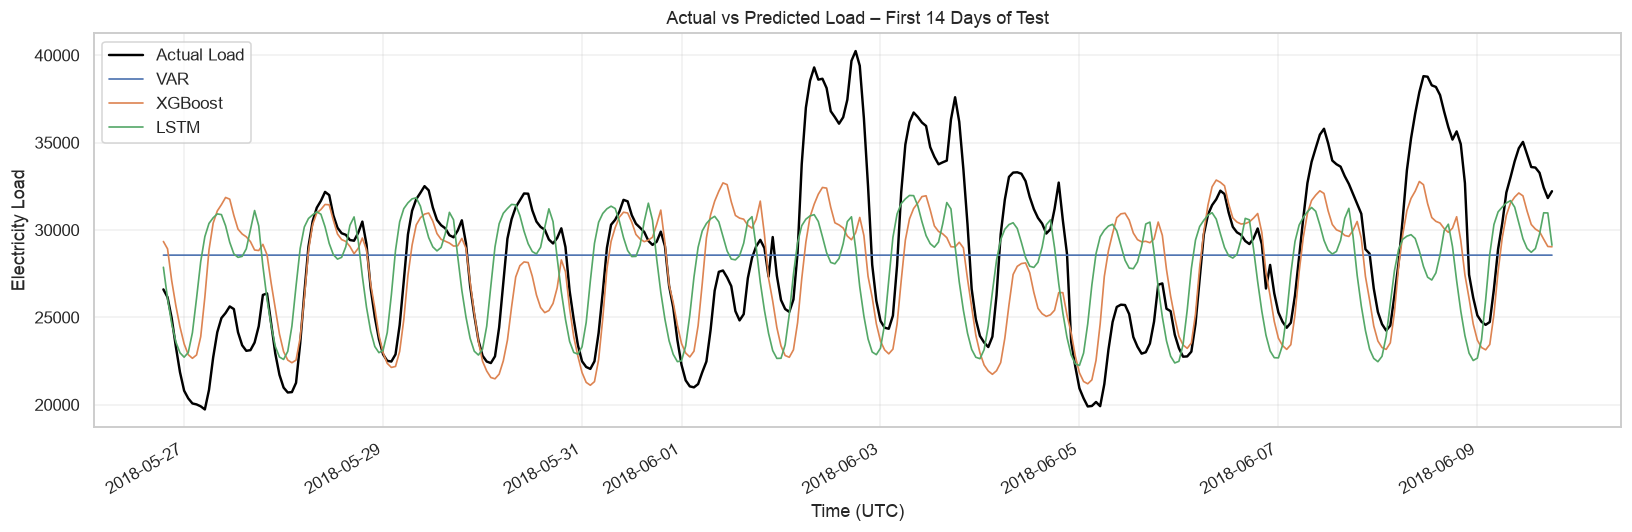

In [42]:
# Hiển thị 14 ngày đầu của Test (24 giờ × 14 ngày)
plot_steps = min(24 * 14, len(test_scaled))
plot_mask = var_test_observed[:plot_steps]
plot_time = test_scaled.index[:plot_steps][plot_mask]

actual_load = inverse_load_scale(test_scaled["load"].to_numpy()[:plot_steps][plot_mask])
var_load_pred = inverse_load_scale(var_test_pred_scaled[:plot_steps][plot_mask])
xgb_load_pred = inverse_load_scale(xgb_test_pred_full[:plot_steps][plot_mask])
lstm_load_pred = inverse_load_scale(lstm_test_pred_full[:plot_steps][plot_mask])

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(plot_time, actual_load, label="Actual Load", color="black", linewidth=1.6)
ax.plot(plot_time, var_load_pred, label="VAR", linewidth=1.1)
ax.plot(plot_time, xgb_load_pred, label="XGBoost", linewidth=1.1)
ax.plot(plot_time, lstm_load_pred, label="LSTM", linewidth=1.1)

ax.set_title("Actual vs Predicted Load – First 14 Days of Test")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Electricity Load")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

log.info("Hoàn thành trực quan hóa dự báo trên Test.")


### **Tạo Score / Model Evaluation Table**

In [43]:
# Tổng hợp bảng đánh giá các mô hình
evaluation_table = metrics_df[
    ["Model", "Dataset", "RMSE", "MAE", "MAPE (%)"]
].copy()

# Sắp xếp theo tập dữ liệu và RMSE
dataset_order = ["Validation", "Test"]

evaluation_table["Dataset"] = pd.Categorical(
    evaluation_table["Dataset"],
    categories=dataset_order,
    ordered=True
)

evaluation_table = (
    evaluation_table
    .sort_values(["Dataset", "RMSE"])
    .reset_index(drop=True)
)

def highlight_evaluation(row):
    best = evaluation_table.loc[evaluation_table["Dataset"] == row["Dataset"], "RMSE"].min()
    color = "#dcfce7" if row["RMSE"] == best else "#f8fafc"
    return [f"background-color: {color}"] * len(row)

print("=== MODEL EVALUATION TABLE ===")
display(style_table(evaluation_table, caption="Phase 9 — Model evaluation comparison", formats={"RMSE": "{:.3f}", "MAE": "{:.3f}", "MAPE (%)": "{:.3f}%"}, row_highlighter=highlight_evaluation))

log.info("Hoàn thành tạo Model Evaluation Table.")

=== MODEL EVALUATION TABLE ===


Model,Dataset,RMSE,MAE,MAPE (%)
LSTM,Validation,3400.397,2666.656,9.385%
XGBoost,Validation,3888.147,3078.316,10.405%
VAR,Validation,4597.912,3886.714,13.643%
XGBoost,Test,3664.482,2935.208,9.948%
VAR,Test,4614.274,3952.871,13.944%
LSTM,Test,4855.826,3884.704,13.350%


In [44]:
# Tạo bảng xếp hạng trên Validation và Test
def create_model_ranking(data, dataset_name):

    ranking = (
        data[data["Dataset"] == dataset_name]
        .sort_values("RMSE")
        .reset_index(drop=True)
        .copy()
    )

    ranking.insert(0, "Rank", range(1, len(ranking) + 1))

    ranking["Status"] = [
        "Best Model" if i == 0 else ""
        for i in range(len(ranking))
    ]

    return ranking


validation_ranking = create_model_ranking(
    evaluation_table, "Validation"
)

test_ranking = create_model_ranking(
    evaluation_table, "Test"
)

def highlight_best_rank(row):
    color = "#dcfce7" if row["Status"] == "Best Model" else "#f8fafc"
    return [f"background-color: {color}"] * len(row)

print("=== VALIDATION MODEL RANKING ===")
display(style_table(validation_ranking, caption="Phase 9 — Validation ranking", formats={"RMSE": "{:.3f}", "MAE": "{:.3f}", "MAPE (%)": "{:.3f}%"}, row_highlighter=highlight_best_rank))

print("=== TEST MODEL RANKING ===")
display(style_table(test_ranking, caption="Phase 9 — Test ranking", formats={"RMSE": "{:.3f}", "MAE": "{:.3f}", "MAPE (%)": "{:.3f}%"}, row_highlighter=highlight_best_rank))

log.info("Hoàn thành bảng xếp hạng mô hình.")

=== VALIDATION MODEL RANKING ===


Rank,Model,Dataset,RMSE,MAE,MAPE (%),Status
1,LSTM,Validation,3400.397,2666.656,9.385%,Best Model
2,XGBoost,Validation,3888.147,3078.316,10.405%,
3,VAR,Validation,4597.912,3886.714,13.643%,


=== TEST MODEL RANKING ===


Rank,Model,Dataset,RMSE,MAE,MAPE (%),Status
1,XGBoost,Test,3664.482,2935.208,9.948%,Best Model
2,VAR,Test,4614.274,3952.871,13.944%,
3,LSTM,Test,4855.826,3884.704,13.350%,


## Phase 10 — Results và Final Report

### Xuất kết quả vào folder results

In [46]:
# PROJECT_ROOT đã được xác định ở cell logging, độc lập với current working directory.
project_root = PROJECT_ROOT

# Tạo thư mục results nếu chưa tồn tại
RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Đường dẫn lưu kết quả
csv_file = RESULTS_DIR / "model_evaluation.csv"
excel_file = RESULTS_DIR / "model_evaluation.xlsx"
val_file = RESULTS_DIR / "validation_ranking.csv"
test_file = RESULTS_DIR / "test_ranking.csv"

# Lưu bảng tổng hợp CSV
evaluation_table.to_csv(
    csv_file,
    index=False,
    encoding="utf-8-sig"
)

# Lưu bảng xếp hạng CSV
validation_ranking.to_csv(
    val_file,
    index=False,
    encoding="utf-8-sig"
)

test_ranking.to_csv(
    test_file,
    index=False,
    encoding="utf-8-sig"
)

# Lưu tất cả bảng vào một file Excel
with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    evaluation_table.to_excel(
        writer,
        sheet_name="All Results",
        index=False
    )

    validation_ranking.to_excel(
        writer,
        sheet_name="Validation",
        index=False
    )

    test_ranking.to_excel(
        writer,
        sheet_name="Test",
        index=False
    )

print("=== MODEL EVALUATION FILES ===")

for file in [csv_file, excel_file, val_file, test_file]:
    print(f"Saved: {file.resolve()}")

log.info("Đã lưu toàn bộ Model Evaluation Tables vào: %s", RESULTS_DIR.resolve())

=== MODEL EVALUATION FILES ===
Saved: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_4/results/model_evaluation.csv
Saved: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_4/results/model_evaluation.xlsx
Saved: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_4/results/validation_ranking.csv
Saved: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_4/results/test_ranking.csv


## **Model Summaries – VAR, XGBoost và LSTM**

In [47]:
# Đường dẫn thư mục lưu Model Summary
project_root = PROJECT_ROOT

RESULTS_DIR = project_root / "results"
MODEL_SUMMARY_DIR = RESULTS_DIR / "model_summaries"
MODEL_SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

print("Model summary directory:", MODEL_SUMMARY_DIR.resolve())
log.info("Model summary directory: %s", MODEL_SUMMARY_DIR.resolve())

Model summary directory: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_4/results/model_summaries


### **VAR Model Summary**

In [48]:
# Tạo VAR Model Summary
var_stats_summary = var_model.summary()
var_stats_text = (
    var_stats_summary.as_text()
    if hasattr(var_stats_summary, "as_text")
    else str(var_stats_summary)
)

var_summary_lines = [
    "VAR MODEL SUMMARY - ELECTRICITY LOAD + WEATHER",
    "=" * 78,
    f"Training observations: {len(train_var_data):,}",
    f"Training period: {train_df['time'].min()} -> {train_df['time'].max()}",
    f"Variables: {', '.join(num_cols)}",
    f"ADF significance level: {alpha}",
    f"Variables differenced: {diff_cols if diff_cols else 'None'}",
    f"Selected lag order (BIC): {var_lag_order}",
    f"Fitted observations: {var_model.nobs:,}",
    f"AIC: {var_model.aic:.6f}",
    f"BIC: {var_model.bic:.6f}",
    f"HQIC: {var_model.hqic:.6f}",
    f"FPE: {var_model.fpe:.6f}",
    "",
    "ADF TEST RESULTS",
    "-" * 78,
    adf_results.to_string(index=False),
    "",
    "STATSMODELS VAR SUMMARY",
    "-" * 78,
    var_stats_text
]

var_summary_text = "\n".join(var_summary_lines)
var_summary_path = MODEL_SUMMARY_DIR / "VAR_summary.txt"
var_summary_path.write_text(var_summary_text, encoding="utf-8")

print(var_summary_text)
print("\nSaved:", var_summary_path.resolve())
log.info("Saved VAR Model Summary: %s", var_summary_path.resolve())


VAR MODEL SUMMARY - ELECTRICITY LOAD + WEATHER
Training observations: 24,544
Training period: 2014-12-31 23:00:00+00:00 -> 2017-10-19 14:00:00+00:00
Variables: load, temperature, humidity, wind_speed
ADF significance level: 0.05
Variables differenced: None
Selected lag order (BIC): 26
Fitted observations: 24,518
AIC: -12.308511
BIC: -12.169633
HQIC: -12.263519
FPE: 0.000005

ADF TEST RESULTS
------------------------------------------------------------------------------
    Feature  ADF Statistic      p-value  Used Lags Stationarity
       load     -19.675511 0.000000e+00         48   Stationary
temperature      -4.617997 1.196551e-04         48   Stationary
   humidity      -6.672654 4.546661e-09         48   Stationary
 wind_speed     -13.362136 5.401614e-25         46   Stationary

STATSMODELS VAR SUMMARY
------------------------------------------------------------------------------
  Summary of Regression Results   
Model:                         VAR
Method:                        O

### **XGBoost Model Summary**

In [49]:
# Tạo XGBoost Model Summary
xgb_params = best_xgb_model.get_params()
xgb_best_iteration = int(
    getattr(best_xgb_model, "best_iteration", best_xgb_record["best_iteration"])
)
xgb_best_rounds = xgb_best_iteration + 1

# Lấy Feature Importance
xgb_importance = pd.DataFrame({
    "Feature": X_train_xgb.columns,
    "Importance": best_xgb_model.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

xgb_top_features = xgb_importance.head(15)

xgb_summary_lines = [
    "XGBOOST MODEL SUMMARY - ELECTRICITY LOAD FORECASTING",
    "=" * 78,
    f"Training samples: {len(X_train_xgb):,}",
    f"Validation samples: {len(X_val_xgb):,}",
    f"Number of input features: {X_train_xgb.shape[1]}",
    "Input: 24-hour lag features for load, temperature, humidity, wind_speed",
    "Additional features: rolling mean (6h), rolling std (24h), load trend (24h)",
    "Target: load at the next time step",
    "",
    "SELECTED HYPERPARAMETERS (BASED ON VALIDATION RMSE)",
    "-" * 78,
    f"Objective: {xgb_params.get('objective')}",
    f"Evaluation metric: {xgb_params.get('eval_metric')}",
    f"Booster: {xgb_params.get('booster')}",
    f"Tree method: {xgb_params.get('tree_method')}",
    f"Max depth: {best_xgb_record['max_depth']}",
    f"Configured n_estimators: {best_xgb_record['n_estimators']}",
    f"Best iteration (0-based): {xgb_best_iteration}",
    f"Best boosting rounds: {xgb_best_rounds}",
    "Early stopping rounds: 50",
    f"Learning rate: {xgb_params.get('learning_rate')}",
    f"Subsample: {xgb_params.get('subsample')}",
    f"Column subsample: {xgb_params.get('colsample_bytree')}",
    f"Random state: {xgb_params.get('random_state')}",
    "",
    "VALIDATION METRICS (ORIGINAL LOAD SCALE)",
    "-" * 78,
    f"MAE: {best_xgb_record['MAE']:.6f}",
    f"RMSE: {best_xgb_record['RMSE']:.6f}",
    f"MAPE: {best_xgb_record['MAPE (%)']:.6f}%",
    "",
    "TOP 15 FEATURE IMPORTANCES",
    "-" * 78,
    xgb_top_features.to_string(index=False, formatters={"Importance": "{:.6f}".format})
]

xgb_summary_text = "\n".join(xgb_summary_lines)
xgb_summary_path = MODEL_SUMMARY_DIR / "XGBoost_summary.txt"
xgb_summary_path.write_text(xgb_summary_text, encoding="utf-8")

# Lưu riêng bảng Feature Importance và kết quả tuning để tiện phân tích
xgb_importance.to_csv(
    MODEL_SUMMARY_DIR / "XGBoost_feature_importance.csv",
    index=False,
    encoding="utf-8-sig"
)

if "xgb_tuning_results" in globals():
    xgb_tuning_results.to_csv(
        MODEL_SUMMARY_DIR / "XGBoost_tuning_results.csv",
        index=False,
        encoding="utf-8-sig"
    )

print(xgb_summary_text)
print("\nSaved:", xgb_summary_path.resolve())
log.info("Saved XGBoost Model Summary: %s", xgb_summary_path.resolve())


XGBOOST MODEL SUMMARY - ELECTRICITY LOAD FORECASTING
Training samples: 24,487
Validation samples: 5,258
Number of input features: 99
Input: 24-hour lag features for load, temperature, humidity, wind_speed
Additional features: rolling mean (6h), rolling std (24h), load trend (24h)
Target: load at the next time step

SELECTED HYPERPARAMETERS (BASED ON VALIDATION RMSE)
------------------------------------------------------------------------------
Objective: reg:squarederror
Evaluation metric: rmse
Booster: None
Tree method: hist
Max depth: 7
Configured n_estimators: 500
Best iteration (0-based): 497
Best boosting rounds: 498
Early stopping rounds: 50
Learning rate: 0.05
Subsample: 0.8
Column subsample: 0.8
Random state: 42

VALIDATION METRICS (ORIGINAL LOAD SCALE)
------------------------------------------------------------------------------
MAE: 3078.316392
RMSE: 3888.146946
MAPE: 10.405300%

TOP 15 FEATURE IMPORTANCES
---------------------------------------------------------------------

### **LSTM Model Summary**

In [50]:
# Tạo LSTM Model Summary
lstm_total_params = sum(p.numel() for p in lstm_model.parameters())
lstm_trainable_params = sum(
    p.numel() for p in lstm_model.parameters() if p.requires_grad
)

lstm_epochs_completed = len(lstm_history["train_loss"])
lstm_best_epoch = int(np.argmin(lstm_history["val_loss"]) + 1)
lstm_best_train_loss = float(lstm_history["train_loss"][lstm_best_epoch - 1])
lstm_best_validation_loss = float(lstm_history["val_loss"][lstm_best_epoch - 1])

lstm_optimizer_name = type(optimizer).__name__
lstm_learning_rate = optimizer.param_groups[0]["lr"]
lstm_batch_size = train_loader.batch_size
lstm_input_shape = tuple(X_train_lstm.shape[1:])

lstm_summary_lines = [
    "LSTM MODEL SUMMARY - ELECTRICITY LOAD FORECASTING",
    "=" * 78,
    f"Training samples: {len(X_train_lstm):,}",
    f"Validation samples: {len(X_val_lstm):,}",
    f"Test samples: {len(X_test_lstm):,}",
    f"Input shape per sample: {lstm_input_shape}",
    f"Input features: {', '.join(num_cols)}",
    "Target: next-step load",
    "",
    "NETWORK ARCHITECTURE",
    "-" * 78,
    f"Layer 1: LSTM(input_size={lstm_model.lstm1.input_size}, hidden_size={lstm_model.lstm1.hidden_size})",
    f"Layer 2: LSTM(input_size={lstm_model.lstm2.input_size}, hidden_size={lstm_model.lstm2.hidden_size})",
    f"Output layer: Linear(in_features={lstm_model.output_layer.in_features}, out_features={lstm_model.output_layer.out_features})",
    f"Total parameters: {lstm_total_params:,}",
    f"Trainable parameters: {lstm_trainable_params:,}",
    "",
    "TRAINING CONFIGURATION",
    "-" * 78,
    f"Loss function: {type(criterion).__name__}",
    f"Optimizer: {lstm_optimizer_name}",
    f"Learning rate: {lstm_learning_rate}",
    f"Batch size: {lstm_batch_size}",
    f"Maximum epochs: {max_epochs}",
    f"Completed epochs: {lstm_epochs_completed}",
    f"Early stopping patience: {patience}",
    f"Best epoch: {lstm_best_epoch}",
    f"Training device: {device}",
    "",
    "BEST EPOCH LOSSES (STANDARDIZED SCALE)",
    "-" * 78,
    f"Train MSE: {lstm_best_train_loss:.8f}",
    f"Validation MSE: {lstm_best_validation_loss:.8f}",
    "Note: These losses are calculated on standardized load values.",
]

lstm_summary_text = "\n".join(lstm_summary_lines)
lstm_summary_path = MODEL_SUMMARY_DIR / "LSTM_summary.txt"
lstm_summary_path.write_text(lstm_summary_text, encoding="utf-8")

# Lưu lịch sử huấn luyện để có thể vẽ Learning Curve hoặc phân tích overfitting
lstm_history_df = pd.DataFrame({
    "Epoch": range(1, lstm_epochs_completed + 1),
    "Train Loss": lstm_history["train_loss"],
    "Validation Loss": lstm_history["val_loss"]
})
lstm_history_df.to_csv(
    MODEL_SUMMARY_DIR / "LSTM_training_history.csv",
    index=False,
    encoding="utf-8-sig"
)

print(lstm_summary_text)
print("\nSaved:", lstm_summary_path.resolve())
log.info("Saved LSTM Model Summary: %s", lstm_summary_path.resolve())


LSTM MODEL SUMMARY - ELECTRICITY LOAD FORECASTING
Training samples: 24,488
Validation samples: 5,258
Test samples: 5,258
Input shape per sample: (24, 4)
Input features: load, temperature, humidity, wind_speed
Target: next-step load

NETWORK ARCHITECTURE
------------------------------------------------------------------------------
Layer 1: LSTM(input_size=4, hidden_size=64)
Layer 2: LSTM(input_size=64, hidden_size=32)
Output layer: Linear(in_features=32, out_features=1)
Total parameters: 30,497
Trainable parameters: 30,497

TRAINING CONFIGURATION
------------------------------------------------------------------------------
Loss function: MSELoss
Optimizer: Adam
Learning rate: 0.001
Batch size: 128
Maximum epochs: 30
Completed epochs: 13
Early stopping patience: 6
Best epoch: 7
Training device: cpu

BEST EPOCH LOSSES (STANDARDIZED SCALE)
------------------------------------------------------------------------------
Train MSE: 0.01945775
Validation MSE: 0.56186758
Note: These losses are

## 11. Trả lời 6 câu hỏi phân tích

Các kết luận dưới đây dựa trên lần chạy hiện tại của notebook với protocol **recursive walk-forward backtesting**.

### 1. Biến thời tiết nào ảnh hưởng mạnh nhất đến điện năng?

Nhiệt độ là biến thời tiết có liên hệ mạnh nhất với `load`. Pearson correlation của nhiệt độ là `0.214`, so với độ ẩm `-0.195` và tốc độ gió `0.094`. Tổng feature importance của các lag nhiệt độ trong XGBoost cũng cao nhất trong ba nhóm thời tiết. Tuy nhiên, đây là bằng chứng về liên hệ thống kê, chưa phải kết luận nhân quả. Mô hình vẫn phụ thuộc chủ yếu vào lịch sử điện năng, đặc biệt là `load_lag_1`.

### 2. Khi nào VAR thất bại?

Trong bài này, VAR thất bại rõ nhất khi dự báo recursive nhiều bước trên quan hệ phi tuyến và có sai số tích lũy. Kết quả Test của VAR là RMSE `4614.27`, MAE `3952.87`, MAPE `13.94%`, kém hơn XGBoost với RMSE `3664.48` và MAPE `9.95%`. VAR là mô hình tuyến tính nên khó mô tả đầy đủ các tương tác phi tuyến giữa điện năng và thời tiết; sai số ở các bước trước tiếp tục được đưa vào các bước sau.

### 3. XGBoost học được thông tin gì từ thời tiết?

XGBoost học các quan hệ trễ giữa thời tiết và điện năng: nhiệt độ, độ ẩm và tốc độ gió của các giờ trước được dùng để hiệu chỉnh dự báo `load` ở giờ kế tiếp. Tuy nhiên, các lag của `load` vẫn chiếm phần lớn feature importance. Vì vậy, thời tiết đóng vai trò thông tin bối cảnh và điều chỉnh dự báo, còn tính liên tục của điện năng là nguồn tín hiệu chính.

### 4. LSTM học được chu kỳ nào: ngày hay tuần?

LSTM sử dụng cửa sổ lịch sử `24 giờ`, nên có cơ sở để học các mẫu trong ngày hoặc intraday. Notebook không sử dụng cửa sổ `168 giờ` và cũng không đưa trực tiếp biến thứ trong tuần vào đầu vào. Vì vậy, chu kỳ ngày có thể được học, nhưng chưa đủ bằng chứng để kết luận LSTM đã học được chu kỳ tuần.

### 5. LSTM có bị overfitting không?

Có dấu hiệu overfitting. Training loss tiếp tục giảm từ `0.4195` xuống `0.0163`, trong khi validation loss tốt nhất ở epoch `7` với giá trị `0.5619` rồi tăng trở lại. Early stopping dừng quá trình ở epoch `13`. Ngoài ra, Test RMSE (`4855.83`) cao hơn Validation RMSE (`3400.40`), cho thấy khả năng tổng quát hóa khi recursive forecasting còn yếu.

### 6. Sự khác biệt giữa Machine Learning và Deep Learning trong bài toán này?

**XGBoost (Machine Learning)** sử dụng các lag và rolling features được tạo trước, học quan hệ phi tuyến bằng các cây quyết định và cho phép diễn giải qua feature importance. Trong lần chạy này, XGBoost đạt kết quả tốt nhất trên Test.

**LSTM (Deep Learning)** nhận tensor tuần tự có dạng `24 × 4` và tự học biểu diễn phụ thuộc theo thời gian. Mô hình ít dễ diễn giải hơn, có nhiều tham số hơn và cần early stopping để hạn chế overfitting. LSTM tốt nhất trên Validation nhưng kém hơn XGBoost trên Test.

**Kết luận:** với dataset và protocol hiện tại, XGBoost tổng quát hóa tốt hơn trên Test; LSTM có khả năng học mẫu tuần tự nhưng nhạy hơn với overfitting và cách thiết kế cửa sổ thời gian.